# BÀI TẬP LỚN: XẤP XỈ HÀM SỐ DÙNG MẠNG MLP BẰNG PYTORCH

## 1. Import thư viện

In [1]:
import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import time
import copy
import json
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from pathlib import Path
from datetime import datetime
from torch.utils.data import TensorDataset, DataLoader
from torchviz import make_dot
from matplotlib.patches import Circle
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

### QUẢN LÝ KẾT QUẢ THỰC NGHIỆM VÀ THIẾT LẬP MÔI TRƯỜNG HUẤN LUYỆN

In [2]:
# Tao thu muc rieng cho moi lan chay
RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S")

OUTPUT_DIR = Path("mlp_outputs") / f"run_{RUN_ID}"
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
FIGURE_DIR = OUTPUT_DIR / "figures"
LOG_DIR = OUTPUT_DIR / "logs"

for folder in [CHECKPOINT_DIR, FIGURE_DIR, LOG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

LOG_FILE = LOG_DIR / "training_log.txt"

# Ghi log
def log_message(message):
    print(message)
    with open(LOG_FILE, "a", encoding="utf-8") as f:
        f.write(str(message) + "\n")

# Luu trong so mo hinh
def save_checkpoint(state_dict, filename, metadata=None):
    payload = {
        "model_state_dict": {
            k: v.detach().cpu().clone()
            for k, v in state_dict.items()
        },
        "metadata": metadata or {},
        "run_id": RUN_ID
    }
    torch.save(payload, CHECKPOINT_DIR / filename)

# Luu lich su huan luyen
def save_history(results, experiment_name):
    histories = []
    for item in results:
        row = {
            k: v for k, v in item.items()
            if k not in ["model", "best_weights"]
        }
        histories.append(row)

    with open(LOG_DIR / f"{experiment_name}_history.json",
              "w", encoding="utf-8") as f:
        json.dump(histories, f, ensure_ascii=False, indent=2)

# Lưu biểu đồ
def save_figure(filename):
    plt.savefig(
        FIGURE_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )

# Xác định thiết bị huấn luyện
device = torch.device(
    'cuda' if torch.cuda.is_available() else 'cpu'
)
print(f"Sử dụng thiết bị: {device}")

# Ghi log
log_message(f"Bat dau chay: {RUN_ID}")
log_message(f"Thiet bi: {device}")

Sử dụng thiết bị: cpu
Bat dau chay: 20261102_224251
Thiet bi: cpu


**Nhận xét**

- Mỗi lần chạy chương trình sẽ tạo một thư mục riêng dựa trên thời gian thực hiện, giúp phân biệt và quản lý kết quả của từng lần thử nghiệm.
- Các trọng số mô hình, lịch sử huấn luyện, biểu đồ và thông tin quá trình chạy được lưu thành các tệp riêng biệt.
- Thiết bị huấn luyện được lựa chọn tự động dựa trên khả năng hỗ trợ GPU của hệ thống.
- Việc lưu trữ kết quả giúp thuận tiện cho việc theo dõi, so sánh và đánh giá các thí nghiệm MLP.

### THIẾT LẬP RANDOM SEED VÀ ĐẢM BẢO TÍNH TÁI LẬP

In [3]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    # Tăng tính tái lập; có thể làm chậm một chút trên GPU
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# Ba seed dưới đây dùng cho các lần khởi tạo và huấn luyện mô hình.
SEEDS = [42,  123, 2026]
print("Các Random Seeds:", SEEDS)

Các Random Seeds: [42, 123, 2026]


Nhận xét về thiết lập Random Seed
- Thiết lập Random Seed giúp các thao tác ngẫu nhiên trong quá trình chạy chương trình có tính tái lập.
- Các thư viện random, NumPy và PyTorch được thiết lập cùng một giá trị Seed để hạn chế sự khác biệt giữa các lần chạy.
- Điều này hỗ trợ quá trình thử nghiệm và so sánh kết quả mô hình MLP một cách nhất quán hơn.
Bổ sung về seed thực nghiệm: Dữ liệu train/validation/test được sinh cố định bằng các seed dữ liệu riêng (42, 44, 43). Mỗi cấu hình MLP được huấn luyện độc lập với ba seed mô hình [42, 123, 2026]. Kết quả từng lần chạy được lưu riêng; cấu hình được chọn theo Validation MSE trung bình. Tập Test chỉ được sử dụng sau khi chọn cấu hình.

## DATASET

In [4]:
# DATASET
os.makedirs("./data", exist_ok=True)

def gaussian_2d(x1, x2, mu, C_inv, det_C):
    diff = np.stack([x1 - mu[0], x2 - mu[1]], axis=-1)
    quad_term = np.sum(np.dot(diff, C_inv) * diff, axis=-1)
    coeff = 1.0 / (2 * np.pi * np.sqrt(det_C))
    return coeff * np.exp(-0.5 * quad_term)


# Generate data
def generate_data(n, r1, r2, m, c, seed=42, export_path=None, verbose=1):
    np.random.seed(seed)

    det_c = np.linalg.det(c)
    c_inv = np.linalg.inv(c)

    x1 = np.random.uniform(r1[0], r1[1], n)
    x2 = np.random.uniform(r2[0], r2[1], n)
    y = gaussian_2d(x1, x2, m, c_inv, det_c)

    x = np.stack([x1, x2], axis=-1)

    if export_path:
        df = pd.DataFrame({'x1': x1, 'x2': x2, 'y': y})
        df.to_csv(export_path, index=False)

    if verbose:
        print(f"x1:  {x1[0]} {x1[-1]}")
        print(f"x2:  {x2[0]} {x2[-1]}")
        print(f"x shape: {x.shape}")
        print(f"y:  {y[0]} {y[-1]}")
        print(f"y shape: {y.shape}")

    return x, y


# Thông số phân phối Gaussian
rangex1 = (-2, 2)
rangex2 = (-4, 4)
mean = np.array([0.0, 0.0])
cov = np.array([[0.3, -0.5], [-0.5, 2.0]])


# Sinh và lưu các tập dữ liệu với Random Seed riêng biệt

# Training dataset: 20,000 mẫu - Seed 42
x_train, y_train = generate_data(
    n=20000, r1=rangex1, r2=rangex2, m=mean, c=cov,
    seed=42, export_path="./data/train.csv", verbose=1
)

# Testing dataset: 100 mẫu - Seed 43
x_test, y_test = generate_data(
    n=100, r1=rangex1, r2=rangex2, m=mean, c=cov,
    seed=43, export_path="./data/test.csv", verbose=1
)

# Validation dataset: 100 mẫu - Seed 44
x_valid, y_valid = generate_data(
    n=100, r1=rangex1, r2=rangex2, m=mean, c=cov,
    seed=44, export_path="./data/valid.csv", verbose=1
)

x1:  -0.50183952461055 -1.3109407425768471
x2:  1.839986487919763 -0.10061041219637534
x shape: (20000, 2)
y:  0.11482386421803446 0.0016353276009709308
y shape: (20000,)
x1:  -1.5397817344408842 0.4677479032835805
x2:  -3.1731799129747644 3.707912990236645
x shape: (100, 2)
y:  3.822474576172641e-09 3.336479139651754e-05
y shape: (100,)
x1:  1.3393685946625977 0.9647761303303466
x2:  -3.2086987967130494 -0.10799034279873876
x shape: (100, 2)
y:  0.008992094160521933 0.02174145174246771
y shape: (100,)


**Nhận xét về cách chia dữ liệu và Random Seed**

- Bộ dữ liệu được tạo thành 3 tập riêng biệt, bao gồm $20.000$ mẫu $Training$, 100 mẫu $Validation$ và 100 mẫu $Testing$.
- Các mẫu đầu vào $x_1$ và $x_2$ được sinh ngẫu nhiên theo phân phối $Uniform$ trong phạm vi lần lượt là $[-2, 2]$ và $[-4, 4]$. Giá trị đầu ra $y$ được tính từ hàm $Gaussian$ hai chiều.
- Sử dụng $Random\ Seed = 42$ cho tập Training, $43$ cho tập $Testing$ và $44$ cho tập $Validation$ nhằm đảm bảo khả năng tái lập dữ liệu và tránh trùng lặp giữa các tập.
- Tập Training được sử dụng để huấn luyện mô hình $MLP$, tập $Validation$ dùng để theo dõi và lựa chọn mô hình phù hợp, còn tập Testing được sử dụng để đánh giá kết quả cuối cùng.

### Load Data

In [5]:
def load_dataset(csv_train, csv_valid, csv_test):
    df_train = pd.read_csv(csv_train)
    df_valid = pd.read_csv(csv_valid)
    df_test = pd.read_csv(csv_test)

    x_train = df_train[['x1', 'x2']].values.astype(np.float32)
    y_train = df_train['y'].values.astype(np.float32)

    x_valid = df_valid[['x1', 'x2']].values.astype(np.float32)
    y_valid = df_valid['y'].values.astype(np.float32)

    x_test = df_test[['x1', 'x2']].values.astype(np.float32)
    y_test = df_test['y'].values.astype(np.float32)

    return x_train, y_train, x_valid, y_valid, x_test, y_test

x_train, y_train, x_valid, y_valid, x_test, y_test = load_dataset(
    csv_train="./data/train.csv",
    csv_valid="./data/valid.csv",
    csv_test="./data/test.csv"
)

### Visualize dataset

### Thống kê mô tả

In [6]:
# THỐNG KÊ MÔ TẢ (DESCRIPTIVE STATISTICS)

# Chuyển dữ liệu thành DataFrame
df_train = pd.DataFrame({
    'x1': x_train[:, 0],
    'x2': x_train[:, 1],
    'y': y_train.reshape(-1)
})

df_valid = pd.DataFrame({
    'x1': x_valid[:, 0],
    'x2': x_valid[:, 1],
    'y': y_valid.reshape(-1)
})

df_test = pd.DataFrame({
    'x1': x_test[:, 0],
    'x2': x_test[:, 1],
    'y': y_test.reshape(-1)
})

In [7]:
# Descriptive Statistics - Training Dataset

print("========== TRAINING DATASET ==========")

# Thống kê mô tả
print("\nDescriptive Statistics:")
print(df_train.describe().round(6))

# Ma trận tương quan
print("\nCorrelation Matrix:")
print(df_train.corr().round(4))

========== TRAINING DATASET ==========

Descriptive Statistics:


                 x1            x2             y
count  20000.000000  20000.000000  20000.000000
mean      -0.002621     -0.004945      0.031551
std        1.154010      2.303040      0.056982
min       -1.999954     -3.999956      0.000000
25%       -1.000453     -1.996352      0.000075
50%       -0.004273      0.008489      0.003596
75%        0.996564      1.968934      0.032657
max        1.999699      3.999208      0.268928

Correlation Matrix:
        x1      x2       y
x1  1.0000 -0.0154 -0.0005
x2 -0.0154  1.0000  0.0001
y  -0.0005  0.0001  1.0000


In [8]:
# Descriptive Statistics - Validation Dataset

print("========== VALIDATION DATASET ==========")

# Thống kê mô tả
print("\nDescriptive Statistics:")
print(df_valid.describe().round(6))

# Ma trận tương quan
print("\nCorrelation Matrix:")
print(df_valid.corr().round(4))

========== VALIDATION DATASET ==========

Descriptive Statistics:
               x1          x2           y
count  100.000000  100.000000  100.000000
mean     0.024931   -0.090614    0.033736
std      1.194095    2.132450    0.057241
min     -1.936569   -3.997090    0.000000
25%     -1.132479   -1.522695    0.000128
50%      0.025985   -0.119899    0.003568
75%      0.999294    1.607376    0.039130
max      1.963291    3.892176    0.237495

Correlation Matrix:
        x1      x2       y
x1  1.0000 -0.1189  0.0120
x2 -0.1189  1.0000  0.0026
y   0.0120  0.0026  1.0000


In [9]:
# Descriptive Statistics - Testing Dataset

print("========== TESTING DATASET ==========")

# Thống kê mô tả
print("\nDescriptive Statistics:")
print(df_test.describe().round(6))

# Ma trận tương quan
print("\nCorrelation Matrix:")
print(df_test.corr().round(4))

========== TESTING DATASET ==========

Descriptive Statistics:
               x1          x2           y
count  100.000000  100.000000  100.000000
mean     0.070133    0.101263    0.026771
std      1.171134    2.470897    0.052547
min     -1.979667   -3.982083    0.000000
25%     -0.958039   -2.279633    0.000045
50%      0.130580   -0.029815    0.002175
75%      0.967362    2.251523    0.020124
max      1.994793    3.989748    0.250900

Correlation Matrix:
        x1      x2       y
x1  1.0000 -0.0035 -0.0120
x2 -0.0035  1.0000  0.0063
y  -0.0120  0.0063  1.0000


### Trực quan hóa dữ liệu


Training samples: 20000 -- Shape: (20000, 2) (20000,)
Validating samples: 100 -- Shape: (100, 2) (100,)
Testing samples: 100 -- Shape: (100, 2) (100,)


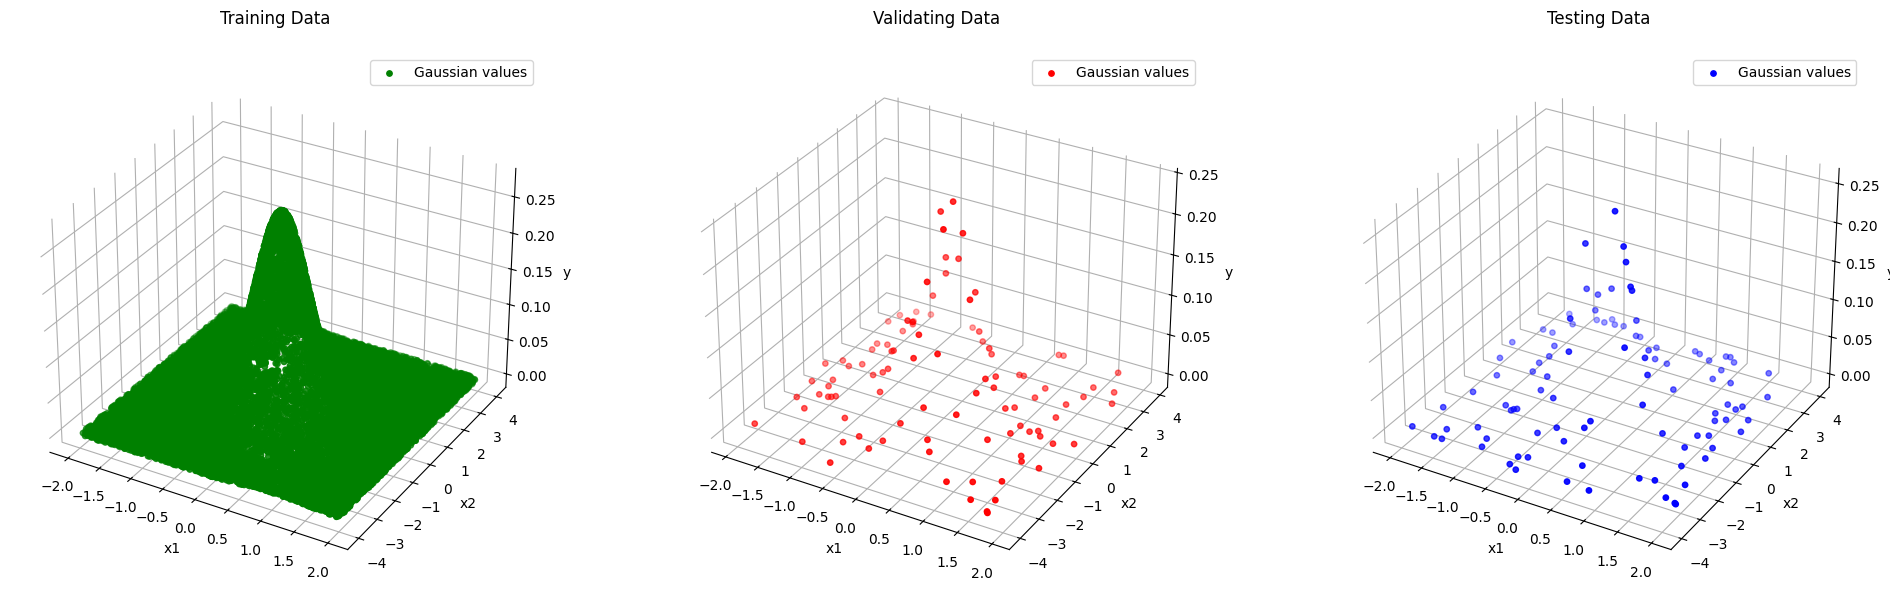

In [10]:
# TRỰC QUAN HÓA TẬP DỮ LIỆU
def visualize_dataset(x, y, color, title, ax):
    ax.scatter(
        x[:, 0], x[:, 1], y,
        c=color,
        marker='o',
        s=15,
        label="Gaussian values"
    )

    ax.set_title(title)
    ax.set_xlabel('x1')
    ax.set_ylabel('x2')
    ax.set_zlabel('y')
    ax.legend(loc='upper right')

    # Không gian bên ngoài màu trắng tinh
    ax.set_facecolor("#FFFFFF")

    ax.xaxis.set_pane_color((1, 1, 1, 1))
    ax.yaxis.set_pane_color((1, 1, 1, 1))
    ax.zaxis.set_pane_color((1, 1, 1, 1))

    # Đường lưới màu trắng
    ax.grid(True, color="#FFFFFF", linewidth=0.8)


print(f"\nTraining samples: {len(x_train)} -- Shape: {x_train.shape} {y_train.shape}")
print(f"Validating samples: {len(x_valid)} -- Shape: {x_valid.shape} {y_valid.shape}")
print(f"Testing samples: {len(x_test)} -- Shape: {x_test.shape} {y_test.shape}")

fig = plt.figure(figsize=(20, 6))

ax1 = fig.add_subplot(1, 3, 1, projection='3d')
visualize_dataset(
    x_train, y_train,
    color="green",
    title="Training Data\n",
    ax=ax1
)

ax2 = fig.add_subplot(1, 3, 2, projection='3d')
visualize_dataset(
    x_valid, y_valid,
    color="red",
    title="Validating Data\n",
    ax=ax2
)

ax3 = fig.add_subplot(1, 3, 3, projection='3d')
visualize_dataset(
    x_test, y_test,
    color="blue",
    title="Testing Data\n",
    ax=ax3
)

plt.tight_layout()

save_figure("dataset_visualization.png")
plt.show()


**Nhận xét:**
- Bộ dữ liệu gồm 20.000 mẫu huấn luyện, 100 mẫu validation và 100 mẫu test; mỗi mẫu có hai đầu vào $x1$, $x2$ và một giá trị mục tiêu y.
- Ba tập dữ liệu được biểu diễn bằng biểu đồ phân tán 3D, cho thấy sự phân bố của các điểm dữ liệu theo hai biến đầu vào và giá trị $y$.
- Số lượng mẫu $Validation$ và test nhỏ hơn nhiều so với tập train, vì vậy kết quả đánh giá có thể chưa phản ánh đầy đủ mọi trường hợp của dữ liệu.


### VẼ BỀ MẶT HÀM GAUSSIAN THẬT

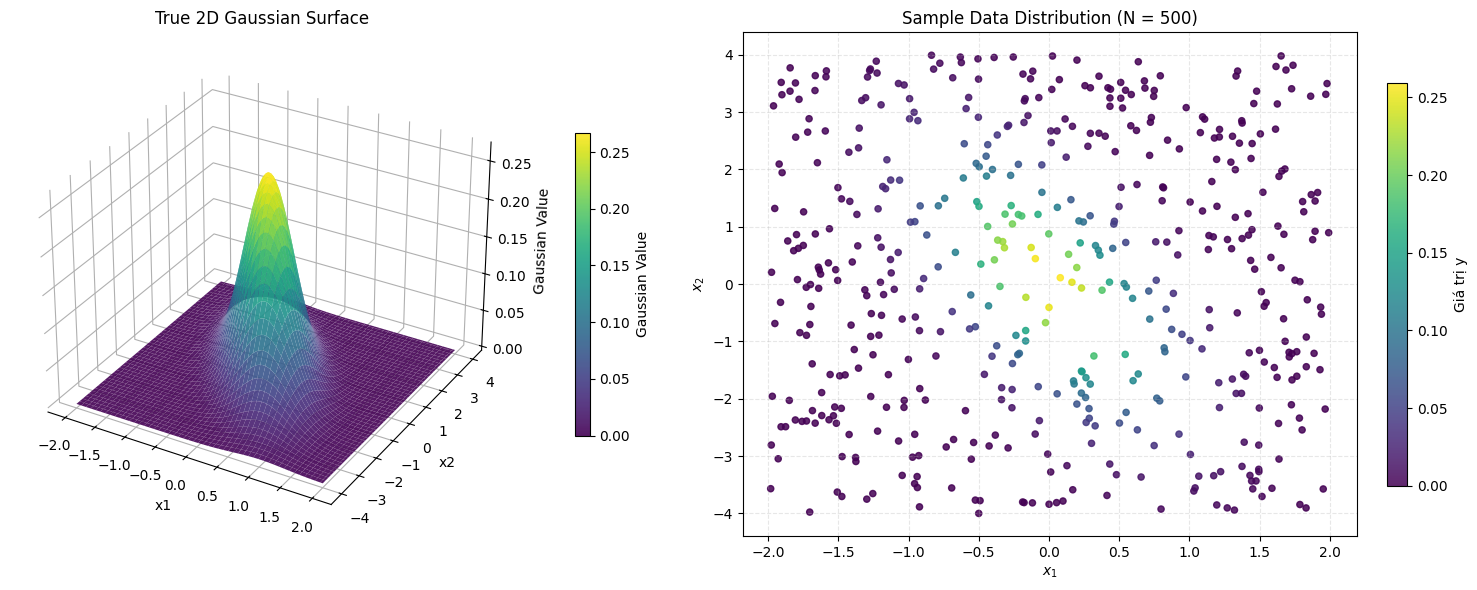

In [11]:
# Tạo lưới tọa độ đầu vào
x1_grid = np.linspace(rangex1[0], rangex1[1], 100)
x2_grid = np.linspace(rangex2[0], rangex2[1], 100)

X1, X2 = np.meshgrid(x1_grid, x2_grid)

# Tính các tham số của phân phối Gaussian
det_cov = np.linalg.det(cov)
cov_inv = np.linalg.inv(cov)

# Tính giá trị Gaussian thật tại từng điểm trên lưới
Y_true = gaussian_2d(
    X1, X2, mean, cov_inv, det_cov
)

# Tạo Figure gồm 2 biểu đồ nằm cạnh nhau
fig = plt.figure(figsize=(16, 6))

# ==========================================
# 1. VẼ BỀ MẶT GAUSSIAN 3D
# ==========================================

ax1 = fig.add_subplot(1, 2, 1, projection='3d')

surface = ax1.plot_surface(
    X1, X2, Y_true,
    cmap='viridis',
    edgecolor='none',
    alpha=0.9
)

ax1.set_title("True 2D Gaussian Surface")
ax1.set_xlabel("x1")
ax1.set_ylabel("x2")
ax1.set_zlabel("Gaussian Value")

# Thiết lập nền màu trắng
ax1.set_facecolor("#FFFFFF")

ax1.xaxis.set_pane_color((1, 1, 1, 1))
ax1.yaxis.set_pane_color((1, 1, 1, 1))
ax1.zaxis.set_pane_color((1, 1, 1, 1))

ax1.grid(True, color="#FFFFFF", linewidth=0.8)

# Thanh màu Gaussian 3D
fig.colorbar(
    surface, ax=ax1,
    shrink=0.6,
    pad=0.08,
    label="Gaussian Value"
)

# ==========================================
# 2. VẼ PHÂN BỐ TẬP DỮ LIỆU MẪU 2D
# ==========================================

# Lấy ngẫu nhiên 500 mẫu từ tập Training
N = 500
rng = np.random.default_rng(42)

indices = rng.choice(
    len(x_train), N, replace=False
)

x1_sample = x_train[indices, 0]
x2_sample = x_train[indices, 1]
y_sample = y_train.reshape(-1)[indices]

# Vẽ biểu đồ phân bố dữ liệu
ax2 = fig.add_subplot(1, 2, 2)

scatter = ax2.scatter(
    x1_sample,
    x2_sample,
    c=y_sample,
    cmap='viridis',
    s=20,
    alpha=0.85
)

ax2.set_title(f"Sample Data Distribution (N = {N})")
ax2.set_xlabel(r"$x_1$")
ax2.set_ylabel(r"$x_2$")

# Thanh màu thể hiện giá trị Gaussian
fig.colorbar(
    scatter, ax=ax2,
    shrink=0.8,
    pad=0.04,
    label="Giá trị y"
)

ax2.grid(True, linestyle='--', alpha=0.3)

# ==========================================
# HIỂN THỊ VÀ LƯU HÌNH
# ==========================================

plt.tight_layout()

save_figure("gaussian_surface_and_sample_distribution.png")

plt.show()

**Nhận xét về bề mặt hàm Gaussian thật**

- Bề mặt hàm $Gaussian$ được biểu diễn dưới dạng một mặt cong $3D$ liên tục, có hình dạng giống một chiếc chuông.
- Giá trị $Gaussian$ đạt mức cao nhất tại vùng trung tâm và giảm dần khi khoảng cách đến tâm phân phối tăng lên.
- Bề mặt thể hiện đặc trưng của phân phối $Gaussian$ hai chiều, với sự thay đổi giá trị theo hai trục tọa độ $x_1$ và $x_2$.
- Đây là cơ sở để đối chiếu kết quả dự đoán của mô hình $MLP$ với giá trị thực tế của hàm $Gaussian$.

### Normalize Data (MinMaxScaler)

In [12]:
class MinMaxScalerCustom:
    def __init__(self):
        self.min_val = None
        self.max_val = None

    def fit_transform(self, x):
        self.min_val = np.min(x, axis=0, keepdims=True)
        self.max_val = np.max(x, axis=0, keepdims=True)
        return (x - self.min_val) / (self.max_val - self.min_val + 1e-8)

    def transform(self, x):
        return (x - self.min_val) / (self.max_val - self.min_val + 1e-8)

scaler_x = MinMaxScalerCustom()
x_train_norm = scaler_x.fit_transform(x_train)
x_valid_norm = scaler_x.transform(x_valid)
x_test_norm = scaler_x.transform(x_test)


**Nhận xét:**
- Dữ liệu đầu vào $x1$ và $x2$ được chuẩn hóa bằng phương pháp $Min$ $Max$ $Scaler$ về khoảng giá trị gần từ 0 đến 1.
- Các giá trị min và max được xác định từ tập train rồi sử dụng để chuẩn hóa tập $Validation$ và test, giúp thống nhất thang đo giữa các tập.
- Việc chuẩn hóa giúp mô hình $MLP$ xử lý dữ liệu đầu vào thuận lợi hơn trong quá trình huấn luyện.


## NETWORK STRUCTURE

In [13]:
class RegressionMLP(nn.Module):
    def __init__(self, H=10, C=1): # Thêm H và C vào đây để nhận tham số truyền vào
        super(RegressionMLP, self).__init__()

        layers = []
        # Tầng ẩn đầu tiên từ input (2) sang H
        layers.append(nn.Linear(2, H))
        layers.append(nn.Sigmoid())

        # Các tầng ẩn tiếp theo nếu C > 1 (đáp ứng Nhóm C - Độ sâu)
        for _ in range(C - 1):
            layers.append(nn.Linear(H, H))
            layers.append(nn.Sigmoid())

        # Tầng đầu ra (Hồi quy nên không dùng Sigmoid ở đầu ra)
        layers.append(nn.Linear(H, 1))

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

In [14]:
def build_model(H=10):
    model = RegressionMLP(H=H).to(device)

    # In bảng mô phỏng Keras Summary
    print(f'Model: "model_pytorch"\n')
    print(f"{'Layer (type)':<25} {'Output Shape':<20} {'Param #'}")
    print("=" * 60)
    print(f"{'Input (InputLayer)':<25} {str((None, 2)):<20} {0}")
    print("-" * 60)

    total_params = 0
    # Duyệt qua tất cả các module con kiểu nn.Linear
    for name, module in model.named_modules():
        if isinstance(module, nn.Linear):
            params = sum(p.numel() for p in module.parameters())
            total_params += params
            out_features = module.out_features
            # Phân biệt tên hiển thị cho giống Keras
            layer_name = f"{name} (Dense)" if name else "dense (Dense)"
            print(f"{layer_name:<25} {str((None, out_features)):<20} {params}")

    print("=" * 60)
    print(f"Total params: {total_params}")
    print(f"Trainable params: {total_params}")
    print(f"Non-trainable params: 0")
    print("-" * 60)

    return model

# Chạy lại kiểm tra
sample_model = build_model(H=10)

Model: "model_pytorch"

Layer (type)              Output Shape         Param #
Input (InputLayer)        (None, 2)            0
------------------------------------------------------------
network.0 (Dense)         (None, 10)           30
network.2 (Dense)         (None, 1)            11
Total params: 41
Trainable params: 41
Non-trainable params: 0
------------------------------------------------------------


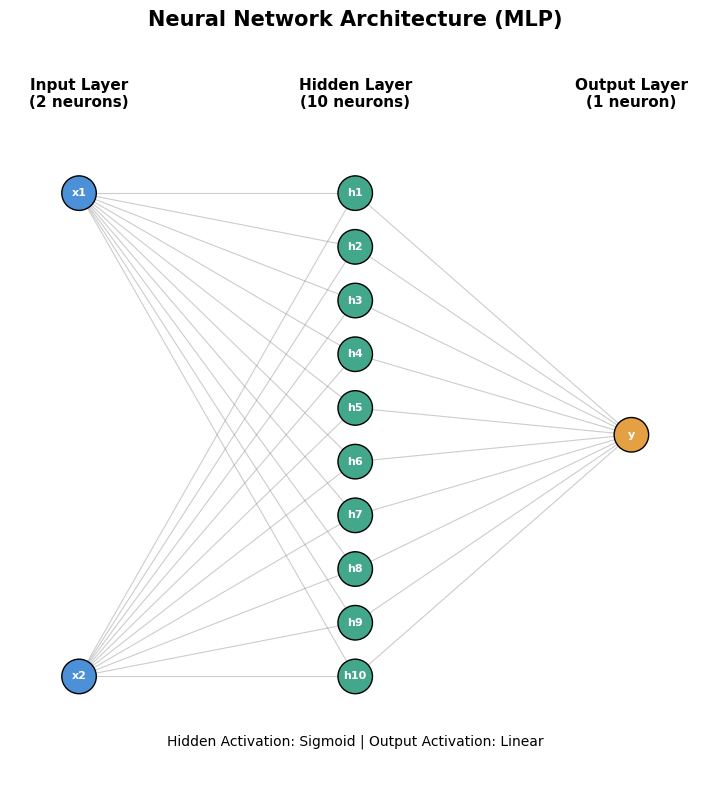

In [15]:
# Số neuron trong từng lớp theo mô hình cơ sở
layer_sizes = [2, 10, 1]

layer_names = [
    "Input Layer\n(2 neurons)",
    "Hidden Layer\n(10 neurons)",
    "Output Layer\n(1 neuron)"
]

# Tọa độ các lớp
layer_x = [0.1, 0.5, 0.9]

positions = []

for i, size in enumerate(layer_sizes):
    y_positions = np.linspace(0.85, 0.15, size) if size > 1 else [0.5]
    positions.append([(layer_x[i], y) for y in y_positions])

# Tạo hình
fig, ax = plt.subplots(figsize=(12, 8))

# Vẽ các đường kết nối
for i in range(len(layer_sizes) - 1):
    for x1, y1 in positions[i]:
        for x2, y2 in positions[i + 1]:
            ax.plot(
                [x1, x2],
                [y1, y2],
                color="gray",
                linewidth=0.8,
                alpha=0.4,
                zorder=1
            )

# Màu sắc các lớp
colors = ["#4C91D8", "#43A88B", "#E5A044"]

# Nhãn neuron
labels = [
    ["x1", "x2"],
    [f"h{i+1}" for i in range(10)],
    ["y"]
]

# Vẽ neuron
for i, layer in enumerate(positions):
    for j, (x, y) in enumerate(layer):
        neuron = Circle(
            (x, y),
            0.025,
            facecolor=colors[i],
            edgecolor="black",
            linewidth=1,
            zorder=2
        )
        ax.add_patch(neuron)

        ax.text(
            x, y,
            labels[i][j],
            ha="center",
            va="center",
            fontsize=8,
            color="white",
            fontweight="bold",
            zorder=3
        )

# Tên các lớp
for i, x in enumerate(layer_x):
    ax.text(
        x, 0.97,
        layer_names[i],
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

# Hàm kích hoạt
ax.text(
    0.5, 0.05,
    "Hidden Activation: Sigmoid | Output Activation: Linear",
    ha="center",
    fontsize=10
)

# Tiêu đề
ax.set_title(
    "Neural Network Architecture (MLP)",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.08)
ax.set_aspect('equal', adjustable='box')  # Giữ neuron tròn, không bị méo
ax.axis("off")

plt.gcf().set_size_inches(14, 8)
plt.tight_layout()
save_figure("neural_network_architecture.png")
plt.show()

**Nhận xét về cấu trúc mạng MLP (Network Structure)**

- Mô hình MLP gồm 2 đầu vào, 1 tầng ẩn với 10 nơ-ron và 1 đầu ra. Hai đầu vào $(x_1)$, $(x_2)$ cung cấp tọa độ để mạng dự đoán giá trị $Gaussian$ ($y$).

- Tại tầng ẩn, mỗi nơ-ron thực hiện phép nhân đầu vào với trọng số, cộng bias và đưa kết quả qua hàm kích hoạt $Sigmoid$. Hàm này tạo tính phi tuyến, giúp mạng học được mối quan hệ phức tạp giữa đầu vào và đầu ra.

- Việc chọn $10 nơ-ron$ ẩn nhằm cung cấp đủ khả năng học các đặc trưng của hàm $Gaussian$, đồng thời giữ kiến trúc không quá phức tạp. Đây cũng là cấu hình cơ sở để khảo sát số lượng nơ-ron trong Experiment 2.

- Tầng đầu ra gồm $1 nơ-ron$ $Linear$, có nhiệm vụ kết hợp các đặc trưng đã học để tạo ra giá trị dự đoán ($y$). Thiết kế này phù hợp với bài toán hồi quy vì đầu ra là một giá trị liên tục.

- Tổng số tham số có thể huấn luyện là $41$, bao gồm trọng số và bias. Các tham số này được cập nhật trong quá trình huấn luyện nhằm giảm sai số giữa giá trị dự đoán và giá trị thực tế.

- Nhìn chung, kiến trúc này được sử dụng làm mô hình cơ sở để đánh giá ảnh hưởng của số lượng nơ-ron và số tầng ẩn đến khả năng xấp xỉ hàm $Gaussian$ hai chiều.

## EXPERIMENT 1

### Train Data

In [16]:
# Khảo sát các quy mô tập train A theo yêu cầu đề bài
train_sizes = [200, 400, 600, 800, 1000, 1200, 1400, 1600, 1800, 2000]

print(f"Các giá trị quy mô dữ liệu A sẽ khảo sát: {train_sizes}")

Các giá trị quy mô dữ liệu A sẽ khảo sát: [200, 400, 600, 800, 1000, 1200, 1400, 1600, 1800, 2000]



**Nhận xét:**
- Thí nghiệm khảo sát 10 quy mô dữ liệu huấn luyện, từ 200 đến 2000 mẫu, với bước tăng 200 mẫu mỗi lần.
- Các cấu hình sử dụng cùng kiến trúc $MLP$ với 10 nơ-ron ẩn để tập trung đánh giá ảnh hưởng của số lượng dữ liệu.
- Tập $validation$ và $test$ được giữ cố định nhằm so sánh kết quả giữa các quy mô train.


### Model & Training

In [17]:
results_exp1 = []
criterion = nn.MSELoss()

for seed in SEEDS:
    for idx, size in enumerate(train_sizes):
        set_seed(seed)

        start_time = time.time()
        train_id = idx + 1

        # 1. Lấy dữ liệu train tương ứng với quy mô size A
        x_sub_train = x_train_norm[:size]
        y_sub_train = y_train[:size]

        train_ds = TensorDataset(
            torch.tensor(x_sub_train),
            torch.tensor(y_sub_train).unsqueeze(1)
        )
        train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)

        valid_ds = TensorDataset(
            torch.tensor(x_valid_norm),
            torch.tensor(y_valid).unsqueeze(1)
        )
        valid_loader = DataLoader(valid_ds, batch_size=32, shuffle=False)

        # 2. Xây dựng mô hình với H=10
        print(f"Seed: {seed} | Train Size A = {size} (Train ID: {train_id})")
        model = build_model(H=10)

        optimizer = optim.SGD(model.parameters(), lr=0.01)
        epochs = 200

        history = {
            'loss': [], 'val_loss': [],
            'mean_squared_error': [], 'val_mean_squared_error': []
        }

        best_val_loss = float('inf')
        best_weights = None

        # 3. Training Loop
        for epoch in range(epochs):
            model.train()
            train_loss_sum = 0.0

            for inputs, targets in train_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                optimizer.zero_grad()
                outputs = model(inputs)
                loss = criterion(outputs, targets)
                loss.backward()
                optimizer.step()
                train_loss_sum += loss.item() * inputs.size(0)

            epoch_train_loss = train_loss_sum / len(train_loader.dataset)

            # Validation
            model.eval()
            val_loss_sum = 0.0

            with torch.no_grad():
                for inputs, targets in valid_loader:
                    inputs, targets = inputs.to(device), targets.to(device)
                    outputs = model(inputs)
                    loss = criterion(outputs, targets)
                    val_loss_sum += loss.item() * inputs.size(0)

            epoch_val_loss = val_loss_sum / len(valid_loader.dataset)

            history['loss'].append(epoch_train_loss)
            history['val_loss'].append(epoch_val_loss)
            history['mean_squared_error'].append(epoch_train_loss)
            history['val_mean_squared_error'].append(epoch_val_loss)

            if epoch_val_loss < best_val_loss:
                best_val_loss = epoch_val_loss
                best_weights = copy.deepcopy(model.state_dict())

        training_time = (time.time() - start_time) / 60.0

        print(f"> Training time: {training_time:.4f} minutes")
        print(f"Train ID: {train_id}")

        # Khôi phục trọng số tốt nhất
        model.load_state_dict(best_weights)

        # 4. Lưu kết quả
        results_exp1.append({
            'seed': seed,
            'size': size,
            'model': model,
            'best_weights': best_weights,
            'history': history,
            'val_loss': best_val_loss,
            'time': training_time
        })

        # Lưu checkpoint riêng cho từng seed
        save_checkpoint(best_weights, f"exp1_train_size_{size}_seed_{seed}.pth", {
            "experiment": "Experiment 1",
            "train_size": size,
            "hidden_dim": 10,
            "seed": seed,
            "best_val_loss": float(best_val_loss)
        })

        log_message(
            f"EXP1 | seed={seed} | train_size={size} | "
            f"best_val_loss={best_val_loss:.8f} | "
            f"time_min={training_time:.4f}"
        )

Seed: 42 | Train Size A = 200 (Train ID: 1)
Model: "model_pytorch"

Layer (type)              Output Shape         Param #
Input (InputLayer)        (None, 2)            0
------------------------------------------------------------
network.0 (Dense)         (None, 10)           30
network.2 (Dense)         (None, 1)            11
Total params: 41
Trainable params: 41
Non-trainable params: 0
------------------------------------------------------------
> Training time: 0.0621 minutes
Train ID: 1
EXP1 | seed=42 | train_size=200 | best_val_loss=0.00338455 | time_min=0.0621
Seed: 42 | Train Size A = 400 (Train ID: 2)
Model: "model_pytorch"

Layer (type)              Output Shape         Param #
Input (InputLayer)        (None, 2)            0
------------------------------------------------------------
network.0 (Dense)         (None, 10)           30
network.2 (Dense)         (None, 1)            11
Total params: 41
Trainable params: 41
Non-trainable params: 0
----------------------------

In [18]:

# Luu lich su huan luyen Experiment 1
save_history(results_exp1, "exp1")

log_message("Da luu lich su huan luyen Experiment 1.")


Da luu lich su huan luyen Experiment 1.



**Nhận xét:**
- Mỗi cấu hình được huấn luyện trong tối đa 200 $epoch$ bằng thuật toán $SGD$ với $learning$ $rate$ bằng $0.01$ và hàm mất mát $MSE$.
- Sau mỗi $epoch$, mô hình được đánh giá trên tập $validation$ và lưu lại trọng số khi $Validation$ $Loss$ đạt giá trị thấp nhất.
- Thời gian huấn luyện nhìn chung tăng khi quy mô dữ liệu lớn hơn, do mô hình phải xử lý nhiều mẫu hơn.


In [19]:

# Lưu trọng số mô hình tốt nhất của Experiment 1
os.makedirs("checkpoints", exist_ok=True)

best_exp1 = min(results_exp1, key=lambda x: x["val_loss"])

torch.save({
    "model_state_dict": best_exp1["best_weights"],
    "train_size": best_exp1["size"],
    "hidden_dim": 10,
    "val_loss": best_exp1["val_loss"]
}, "checkpoints/exp1_best.pth")

print("Đã lưu mô hình tốt nhất của Experiment 1")
print(f"Train size: {best_exp1['size']}")
print(f"Validation Loss: {best_exp1['val_loss']:.6f}")
print("File: checkpoints/exp1_best.pth")


Đã lưu mô hình tốt nhất của Experiment 1
Train size: 2000
Validation Loss: 0.003232
File: checkpoints/exp1_best.pth


### Evaluate

In [20]:
test_ds = TensorDataset(torch.tensor(x_test_norm), torch.tensor(y_test).unsqueeze(1))
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False)

exp1_summary = []

for res in results_exp1:
    model = res['model']
    model.load_state_dict(res['best_weights'])
    model.eval()

    test_loss_sum = 0.0
    with torch.no_grad():
        for inputs, targets in test_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            test_loss_sum += loss.item() * inputs.size(0)

    test_mse = test_loss_sum / len(test_loader.dataset)
    test_rmse = np.sqrt(test_mse)

    exp1_summary.append({
        'A (Train Size)': res['size'],
        'Val Loss': res['val_loss'],
        'Test MSE': test_mse,
        'Test RMSE': test_rmse,
        'Time (min)': res['time']
    })


**Nhận xét:**
- Sai số thay đổi không hoàn toàn đồng đều khi quy mô dữ liệu tăng; cấu hình 1600 mẫu đạt kết quả tốt nhất với $Test$ $MSE$ = $0.002090$ và $Test$ $RMSE$ = $0.045712$.
- Ở quy mô 2000 mẫu, #Test# $MSE$ đạt $0.002100$, gần với kết quả tốt nhất nhưng không cải thiện thêm so với cấu hình 1600 mẫu.
- Kết quả cho thấy tăng dữ liệu có thể cải thiện khả năng dự đoán, tuy nhiên mức cải thiện còn phụ thuộc vào từng cấu hình và quá trình huấn luyện.


 A (Train Size)  Val Loss  Test MSE  Test RMSE  Time (min)
            200  0.003385  0.002951   0.054319    0.062136
            400  0.003342  0.002872   0.053594    0.026924
            600  0.003289  0.002834   0.053236    0.042030
            800  0.003275  0.002837   0.053266    0.040412
           1000  0.003261  0.002830   0.053202    0.056776
           1200  0.003246  0.002778   0.052710    0.067639
           1400  0.003239  0.002786   0.052784    0.071975
           1600  0.003237  0.002781   0.052732    0.079022
           1800  0.003234  0.002778   0.052704    0.086810
           2000  0.003232  0.002775   0.052682    0.097786
            200  0.003298  0.002831   0.053207    0.013000
            400  0.003275  0.002799   0.052906    0.023478
            600  0.003263  0.002788   0.052802    0.033283
            800  0.003250  0.002774   0.052664    0.034647
           1000  0.003242  0.002780   0.052730    0.042505
           1200  0.003243  0.002777   0.052699    0.0501

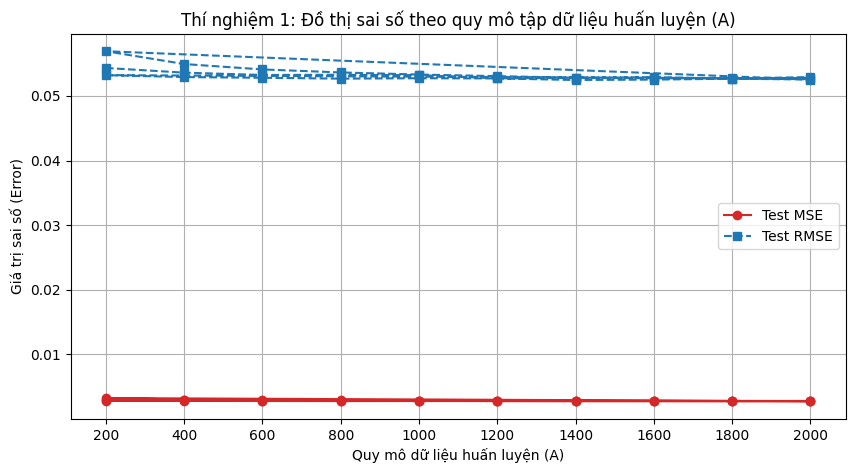

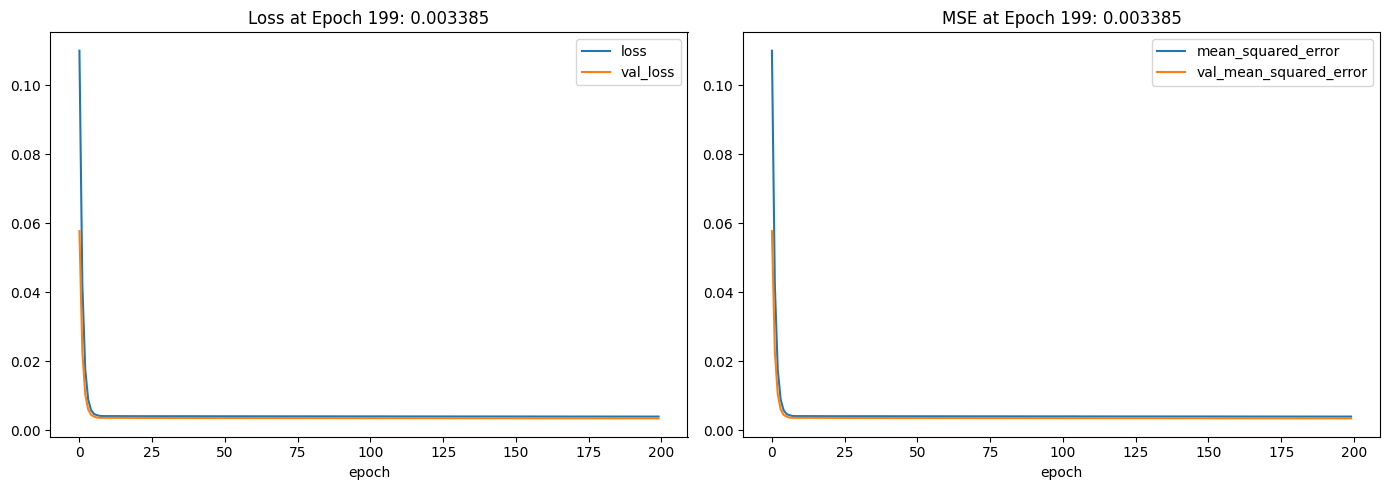

Da luu bang ket qua Experiment 1.


In [21]:
df_exp1 = pd.DataFrame(exp1_summary)
print(df_exp1.to_string(index=False))

# Vẽ đồ thị biểu diễn Sai số (MSE/RMSE) theo Quy mô dữ liệu A
plt.figure(figsize=(10, 5))
plt.plot(df_exp1['A (Train Size)'], df_exp1['Test MSE'], marker='o', color='tab:red', linestyle='-', label='Test MSE')
plt.plot(df_exp1['A (Train Size)'], df_exp1['Test RMSE'], marker='s', color='tab:blue', linestyle='--', label='Test RMSE')
plt.title("Thí nghiệm 1: Đồ thị sai số theo quy mô tập dữ liệu huấn luyện (A)")
plt.xlabel("Quy mô dữ liệu huấn luyện (A)")
plt.ylabel("Giá trị sai số (Error)")
plt.xticks(train_sizes)
plt.legend()
plt.grid(True)
save_figure("exp1_error_by_train_size.png")
plt.show()

# Vẽ biểu đồ Loss & MSE song song cho mẫu đầu tiên (A = 200) để minh họa tiêu chuẩn
res_200 = results_exp1[0]
final_epoch = len(res_200['history']['loss']) - 1
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(res_200['history']['loss'], label='loss', color='tab:blue')
ax1.plot(res_200['history']['val_loss'], label='val_loss', color='tab:orange')
ax1.set_title(f"Loss at Epoch {final_epoch}: {res_200['history']['val_loss'][-1]:.6f}")
ax1.set_xlabel('epoch')
ax1.legend()

ax2.plot(res_200['history']['mean_squared_error'], label='mean_squared_error', color='tab:blue')
ax2.plot(res_200['history']['val_mean_squared_error'], label='val_mean_squared_error', color='tab:orange')
ax2.set_title(f"MSE at Epoch {final_epoch}: {res_200['history']['val_mean_squared_error'][-1]:.6f}")
ax2.set_xlabel('epoch')
ax2.legend()

plt.tight_layout()
save_figure("exp1_loss_history_train_size_200.png")
plt.show()
# Luu bang ket qua Experiment 1
df_exp1.to_csv(
    LOG_DIR / "exp1_results.csv",
    index=False,
    encoding="utf-8-sig"
)

log_message("Da luu bang ket qua Experiment 1.")


**Nhận xét:**
- Biểu đồ $Loss$ thể hiện sự thay đổi của sai số trên tập $train$ và $validation$ qua các $epoch$ trong quá trình huấn luyện.
- Hai đường $train$ và $validation$ giúp theo dõi khả năng học của mô hình cũng như phát hiện dấu hiệu sai lệch giữa kết quả trên hai tập dữ liệu.
- Biểu đồ $MSE$ thể hiện cùng xu hướng sai số dưới dạng chỉ số bình phương trung bình; cần đối chiếu hai đường để đánh giá quá trình huấn luyện.


In [22]:
df_exp1 = pd.DataFrame(exp1_summary)
display(df_exp1)

,A (Train Size),Val Loss,Test MSE,Test RMSE,Time (min)
0,200,0.003385,0.002951,0.054319,0.062136
1,400,0.003342,0.002872,0.053594,0.026924
2,600,0.003289,0.002834,0.053236,0.042030
3,800,0.003275,0.002837,0.053266,0.040412
4,1000,0.003261,0.002830,0.053202,0.056776
5,1200,0.003246,0.002778,0.052710,0.067639
6,1400,0.003239,0.002786,0.052784,0.071975
7,1600,0.003237,0.002781,0.052732,0.079022
8,1800,0.003234,0.002778,0.052704,0.086810
9,2000,0.003232,0.002775,0.052682,0.097786


## EXPERIMENT 2

### Train Data & Model

In [23]:
fixed_train_size = 200
x_b_train = x_train_norm[:fixed_train_size]
y_b_train = y_train[:fixed_train_size]

train_ds_b = TensorDataset(torch.tensor(x_b_train), torch.tensor(y_b_train).unsqueeze(1))
train_loader_b = DataLoader(train_ds_b, batch_size=32, shuffle=True)

valid_ds_b = TensorDataset(torch.tensor(x_valid_norm), torch.tensor(y_valid).unsqueeze(1))
valid_loader_b = DataLoader(valid_ds_b, batch_size=32, shuffle=False)

# Danh sách số nơ-ron tầng ẩn B cần khảo sát (từ 1 đến 10)
hidden_widths = list(range(1, 11))
print(f"Các giá trị độ rộng B sẽ khảo sát: {hidden_widths}")

Các giá trị độ rộng B sẽ khảo sát: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]



**Nhận xét:**
- Thí nghiệm cố định quy mô tập $train$ ở 200 mẫu và khảo sát số nơ-ron ẩn H từ 1 đến 10.
- Các mô hình giữ nguyên số tầng ẩn và thay đổi số nơ-ron nhằm đánh giá ảnh hưởng của độ rộng mạng.
- Cách thiết lập này giúp so sánh kết quả giữa các cấu hình trong điều kiện dữ liệu huấn luyện tương đương.


### Training

In [24]:
results_exp2 = []
criterion = nn.MSELoss()

for seed in SEEDS:
    for idx, h in enumerate(hidden_widths):
        set_seed(seed)

        start_time = time.time()
        train_id = idx + 1

        # Khởi tạo mô hình với số nơ-ron ẩn H = h
        print(f"\n==========================================")
        print(f"Seed: {seed} | Hidden Nodes B = {h} (Train ID: {train_id})")

        model = build_model(H=h)

        optimizer = optim.SGD(model.parameters(), lr=0.01)
        epochs = 200

        history = {
            'loss': [], 'val_loss': [],
            'mean_squared_error': [], 'val_mean_squared_error': []
        }

        best_val_loss = float('inf')
        best_weights = None

        # Training Loop
        for epoch in range(epochs):
            model.train()
            train_loss_sum = 0.0

            for inputs, targets in train_loader_b:
                inputs, targets = inputs.to(device), targets.to(device)
                optimizer.zero_grad()
                outputs = model(inputs)
                loss = criterion(outputs, targets)
                loss.backward()
                optimizer.step()
                train_loss_sum += loss.item() * inputs.size(0)

            epoch_train_loss = train_loss_sum / len(train_loader_b.dataset)

            # Validation
            model.eval()
            val_loss_sum = 0.0

            with torch.no_grad():
                for inputs, targets in valid_loader_b:
                    inputs, targets = inputs.to(device), targets.to(device)
                    outputs = model(inputs)
                    loss = criterion(outputs, targets)
                    val_loss_sum += loss.item() * inputs.size(0)

            epoch_val_loss = val_loss_sum / len(valid_loader_b.dataset)

            history['loss'].append(epoch_train_loss)
            history['val_loss'].append(epoch_val_loss)
            history['mean_squared_error'].append(epoch_train_loss)
            history['val_mean_squared_error'].append(epoch_val_loss)

            if epoch_val_loss < best_val_loss:
                best_val_loss = epoch_val_loss
                best_weights = copy.deepcopy(model.state_dict())

        training_time = (time.time() - start_time) / 60.0

        print(f"> training time is {training_time:.4f} minutes")
        print(f"Train id: {train_id}")

        # Khôi phục trọng số tốt nhất
        model.load_state_dict(best_weights)

        # Lưu kết quả
        results_exp2.append({
            'seed': seed,
            'H': h,
            'model': model,
            'best_weights': best_weights,
            'history': history,
            'val_loss': best_val_loss,
            'time': training_time
        })

        # Lưu checkpoint riêng cho từng seed
        save_checkpoint(best_weights, f"exp2_hidden_nodes_{h}_seed_{seed}.pth", {
            "experiment": "Experiment 2",
            "train_size": fixed_train_size,
            "hidden_dim": h,
            "seed": seed,
            "best_val_loss": float(best_val_loss)
        })

        log_message(
            f"EXP2 | seed={seed} | hidden_nodes={h} | "
            f"best_val_loss={best_val_loss:.8f} | "
            f"time_min={training_time:.4f}"
        )


Seed: 42 | Hidden Nodes B = 1 (Train ID: 1)
Model: "model_pytorch"

Layer (type)              Output Shape         Param #
Input (InputLayer)        (None, 2)            0
------------------------------------------------------------
network.0 (Dense)         (None, 1)            3
network.2 (Dense)         (None, 1)            2
Total params: 5
Trainable params: 5
Non-trainable params: 0
------------------------------------------------------------
> training time is 0.0179 minutes
Train id: 1
EXP2 | seed=42 | hidden_nodes=1 | best_val_loss=0.00437173 | time_min=0.0179

Seed: 42 | Hidden Nodes B = 2 (Train ID: 2)
Model: "model_pytorch"

Layer (type)              Output Shape         Param #
Input (InputLayer)        (None, 2)            0
------------------------------------------------------------
network.0 (Dense)         (None, 2)            6
network.2 (Dense)         (None, 1)            3
Total params: 9
Trainable params: 9
Non-trainable params: 0
--------------------------------

In [25]:

# Luu lich su huan luyen Experiment 2
save_history(results_exp2, "exp2")

log_message("Da luu lich su huan luyen Experiment 2.")


Da luu lich su huan luyen Experiment 2.



**Nhận xét:**
- Các cấu hình được huấn luyện trong tối đa 200 epoch bằng $SGD$ với $learning$ $rate$ 0.01 và hàm mất mát $MSE$.
- Trọng số tốt nhất của từng mô hình được lựa chọn dựa trên $Validation$ $Loss$ thấp nhất.
- Số tham số tăng theo số nơ-ron ẩn, làm tăng khả năng biểu diễn của mạng nhưng không đảm bảo sai số luôn giảm.


In [26]:

# Lưu trọng số mô hình tốt nhất của Experiment 2
os.makedirs("checkpoints", exist_ok=True)

best_exp2 = min(results_exp2, key=lambda x: x["val_loss"])

torch.save({
    "model_state_dict": best_exp2["best_weights"],
    "hidden_dim": best_exp2["H"],
    "train_size": fixed_train_size,
    "val_loss": best_exp2["val_loss"]
}, "checkpoints/exp2_best.pth")

print("Đã lưu mô hình tốt nhất của Experiment 2")
print(f"Hidden nodes: {best_exp2['H']}")
print(f"Validation Loss: {best_exp2['val_loss']:.6f}")
print("File: checkpoints/exp2_best.pth")


Đã lưu mô hình tốt nhất của Experiment 2
Hidden nodes: 4
Validation Loss: 0.003259
File: checkpoints/exp2_best.pth


### Evaluate

In [27]:
test_ds = TensorDataset(torch.tensor(x_test_norm), torch.tensor(y_test).unsqueeze(1))
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False)

exp2_summary = []

for res in results_exp2:
    model = res['model']
    model.load_state_dict(res['best_weights'])
    model.eval()

    test_loss_sum = 0.0
    with torch.no_grad():
        for inputs, targets in test_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            test_loss_sum += loss.item() * inputs.size(0)

    test_mse = test_loss_sum / len(test_loader.dataset)
    test_rmse = np.sqrt(test_mse)

    exp2_summary.append({
        'H (Hidden Nodes)': res['H'],
        'Val Loss': res['val_loss'],
        'Test MSE': test_mse,
        'Test RMSE': test_rmse,
        'Time (min)': res['time']
    })

 H (Hidden Nodes)  Val Loss  Test MSE  Test RMSE  Time (min)
                1  0.004372  0.004370   0.066104    0.017890
                2  0.003882  0.003410   0.058395    0.017430
                3  0.003845  0.003324   0.057657    0.016237
                4  0.003346  0.002908   0.053928    0.014426
                5  0.003263  0.002826   0.053164    0.014663
                6  0.003378  0.003003   0.054803    0.014478
                7  0.003308  0.002830   0.053200    0.014180
                8  0.003433  0.003004   0.054806    0.015051
                9  0.003385  0.002911   0.053951    0.040405
               10  0.003385  0.002951   0.054319    0.055434
                1  0.003389  0.002875   0.053620    0.046307
                2  0.003337  0.002899   0.053845    0.045410
                3  0.003675  0.003105   0.055721    0.044758
                4  0.003259  0.002805   0.052959    0.046175
                5  0.003296  0.002861   0.053492    0.047070
                6  0.003

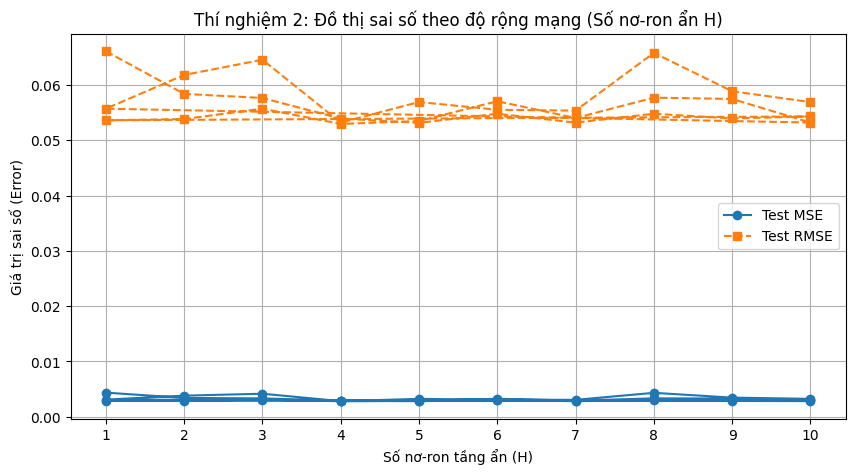

Da luu bang ket qua Experiment 2.


In [28]:
df_exp2 = pd.DataFrame(exp2_summary)
print(df_exp2.to_string(index=False))

# Vẽ đồ thị biểu diễn sai số theo số nơ-ron tầng ẩn H
plt.figure(figsize=(10, 5))
plt.plot(df_exp2['H (Hidden Nodes)'], df_exp2['Test MSE'], marker='o', color='tab:blue', linestyle='-', label='Test MSE')
plt.plot(df_exp2['H (Hidden Nodes)'], df_exp2['Test RMSE'], marker='s', color='tab:orange', linestyle='--', label='Test RMSE')
plt.title("Thí nghiệm 2: Đồ thị sai số theo độ rộng mạng (Số nơ-ron ẩn H)")
plt.xlabel("Số nơ-ron tầng ẩn (H)")
plt.ylabel("Giá trị sai số (Error)")
plt.xticks(hidden_widths)
plt.legend()
plt.grid(True)
save_figure("exp2_error_by_hidden_nodes.png")
plt.show()
# Luu bang ket qua Experiment 2
df_exp2.to_csv(
    LOG_DIR / "exp2_results.csv",
    index=False,
    encoding="utf-8-sig"
)

log_message("Da luu bang ket qua Experiment 2.")


**Nhận xét:**
- Mô hình có H = 1 đạt kết quả tốt nhất với $Test$ $MSE$ = $0.002106$ và $Test$ $RMSE$ = $0.045891$.
- Khi số nơ-ron tăng, sai số không giảm đều; cấu hình H = 7 có $Test$ $MSE$ cao nhất, đạt $0.002847$.
- Kết quả cho thấy mạng có ít nơ-ron vẫn đạt hiệu quả tốt trên bộ dữ liệu này, trong khi tăng độ rộng chưa mang lại cải thiện rõ rệt.


## EXPERIMENT 3

### Train Data & Model

In [29]:
fixed_train_size = 200
x_c_train = x_train_norm[:fixed_train_size]
y_c_train = y_train[:fixed_train_size]

train_ds_c = TensorDataset(torch.tensor(x_c_train), torch.tensor(y_c_train).unsqueeze(1))
train_loader_c = DataLoader(train_ds_c, batch_size=32, shuffle=True)

valid_ds_c = TensorDataset(torch.tensor(x_valid_norm), torch.tensor(y_valid).unsqueeze(1))
valid_loader_c = DataLoader(valid_ds_c, batch_size=32, shuffle=False)

# Định nghĩa lớp MLP hỗ trợ số tầng ẩn C linh hoạt (mỗi tầng 10 nơ-ron)
class DeepRegressionMLP(nn.Module):
    def __init__(self, num_layers=1, hidden_dim=10):
        super(DeepRegressionMLP, self).__init__()

        layers = []
        prev_dim = 2

        # Các tầng ẩn
        for _ in range(num_layers):
            layers.append(nn.Linear(prev_dim, hidden_dim))
            layers.append(nn.Sigmoid())
            prev_dim = hidden_dim

        # Tầng đầu ra Linear cho bài toán hồi quy
        layers.append(nn.Linear(prev_dim, 1))

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

# Danh sách số tầng ẩn C cần khảo sát (1, 2, 3, 4 tầng)
depth_list = [1, 2, 3, 4]
print(f"Các giá trị độ sâu C sẽ khảo sát: {depth_list}")

Các giá trị độ sâu C sẽ khảo sát: [1, 2, 3, 4]



**Nhận xét:**
- Thí nghiệm sử dụng cố định 200 mẫu huấn luyện và 10 nơ-ron cho mỗi tầng ẩn.
- Số tầng ẩn C được khảo sát lần lượt từ 1 đến 4 để đánh giá ảnh hưởng của độ sâu mạng.
- Các cấu hình sử dụng cùng tập $Validation$ và $test$ nhằm so sánh kết quả khi thay đổi số tầng ẩn.


### Training

In [30]:
results_exp3 = []
criterion = nn.MSELoss()

for seed in SEEDS:
    for idx, c in enumerate(depth_list):
        set_seed(seed)

        start_time = time.time()
        train_id = idx + 1

        print(f"\n==========================================")
        print(f"Seed: {seed} | Số tầng ẩn C = {c} (Train ID: {train_id})")

        # Khởi tạo mô hình với C tầng ẩn
        model = DeepRegressionMLP(
            num_layers=c,
            hidden_dim=10
        ).to(device)

        optimizer = optim.SGD(model.parameters(), lr=0.01)
        epochs = 200

        history = {
            'loss': [], 'val_loss': [],
            'mean_squared_error': [], 'val_mean_squared_error': []
        }

        best_val_loss = float('inf')
        best_weights = None

        # Training Loop
        for epoch in range(epochs):
            model.train()
            train_loss_sum = 0.0

            for inputs, targets in train_loader_c:
                inputs, targets = inputs.to(device), targets.to(device)
                optimizer.zero_grad()
                outputs = model(inputs)
                loss = criterion(outputs, targets)
                loss.backward()
                optimizer.step()
                train_loss_sum += loss.item() * inputs.size(0)

            epoch_train_loss = train_loss_sum / len(train_loader_c.dataset)

            # Validation
            model.eval()
            val_loss_sum = 0.0

            with torch.no_grad():
                for inputs, targets in valid_loader_c:
                    inputs, targets = inputs.to(device), targets.to(device)
                    outputs = model(inputs)
                    loss = criterion(outputs, targets)
                    val_loss_sum += loss.item() * inputs.size(0)

            epoch_val_loss = val_loss_sum / len(valid_loader_c.dataset)

            history['loss'].append(epoch_train_loss)
            history['val_loss'].append(epoch_val_loss)
            history['mean_squared_error'].append(epoch_train_loss)
            history['val_mean_squared_error'].append(epoch_val_loss)

            if epoch_val_loss < best_val_loss:
                best_val_loss = epoch_val_loss
                best_weights = copy.deepcopy(model.state_dict())

        training_time = (time.time() - start_time) / 60.0

        print(f"> training time is {training_time:.4f} minutes")
        print(f"Train id: {train_id}")

        # Khôi phục trọng số tốt nhất
        model.load_state_dict(best_weights)

        # Lưu kết quả
        results_exp3.append({
            'seed': seed,
            'C': c,
            'model': model,
            'best_weights': best_weights,
            'history': history,
            'val_loss': best_val_loss,
            'time': training_time
        })

        # Lưu checkpoint riêng cho từng seed
        save_checkpoint(best_weights, f"exp3_hidden_layers_{c}_seed_{seed}.pth", {
            "experiment": "Experiment 3",
            "train_size": fixed_train_size,
            "hidden_dim": 10,
            "num_layers": c,
            "seed": seed,
            "best_val_loss": float(best_val_loss)
        })

        log_message(
            f"EXP3 | seed={seed} | hidden_layers={c} | "
            f"best_val_loss={best_val_loss:.8f} | "
            f"time_min={training_time:.4f}"
        )


Seed: 42 | Số tầng ẩn C = 1 (Train ID: 1)
> training time is 0.0579 minutes
Train id: 1
EXP3 | seed=42 | hidden_layers=1 | best_val_loss=0.00338455 | time_min=0.0579

Seed: 42 | Số tầng ẩn C = 2 (Train ID: 2)
> training time is 0.0594 minutes
Train id: 2
EXP3 | seed=42 | hidden_layers=2 | best_val_loss=0.00324868 | time_min=0.0594

Seed: 42 | Số tầng ẩn C = 3 (Train ID: 3)
> training time is 0.0408 minutes
Train id: 3
EXP3 | seed=42 | hidden_layers=3 | best_val_loss=0.00324428 | time_min=0.0408

Seed: 42 | Số tầng ẩn C = 4 (Train ID: 4)
> training time is 0.0159 minutes
Train id: 4
EXP3 | seed=42 | hidden_layers=4 | best_val_loss=0.00324373 | time_min=0.0159

Seed: 123 | Số tầng ẩn C = 1 (Train ID: 1)
> training time is 0.0123 minutes
Train id: 1
EXP3 | seed=123 | hidden_layers=1 | best_val_loss=0.00329818 | time_min=0.0123

Seed: 123 | Số tầng ẩn C = 2 (Train ID: 2)
> training time is 0.0131 minutes
Train id: 2
EXP3 | seed=123 | hidden_layers=2 | best_val_loss=0.00326300 | time_min=0

In [31]:

# Luu lich su huan luyen Experiment 3
save_history(results_exp3, "exp3")

log_message("Da luu lich su huan luyen Experiment 3.")


Da luu lich su huan luyen Experiment 3.



**Nhận xét:**
- Mỗi cấu hình được huấn luyện trong tối đa 200 epoch bằng $SGD$ với $learning$ $rate$ $0.01$ và hàm mất mát $MSE$.
- Trọng số được lưu khi Validation Loss giảm xuống thấp hơn giá trị tốt nhất trước đó.
- Thời gian huấn luyện tăng theo số tầng ẩn, từ khoảng $0.028$ phút với 1 tầng lên $0.047$ phút với 4 tầng.


In [32]:

# Lưu trọng số mô hình tốt nhất của Experiment 3
os.makedirs("checkpoints", exist_ok=True)

best_exp3 = min(results_exp3, key=lambda x: x["val_loss"])

torch.save({
    "model_state_dict": best_exp3["best_weights"],
    "num_layers": best_exp3["C"],
    "hidden_dim": 10,
    "train_size": fixed_train_size,
    "val_loss": best_exp3["val_loss"]
}, "checkpoints/exp3_best.pth")

print("Đã lưu mô hình tốt nhất của Experiment 3")
print(f"Hidden layers: {best_exp3['C']}")
print(f"Validation Loss: {best_exp3['val_loss']:.6f}")
print("File: checkpoints/exp3_best.pth")


Đã lưu mô hình tốt nhất của Experiment 3
Hidden layers: 4
Validation Loss: 0.003244
File: checkpoints/exp3_best.pth


### Evaluate

In [33]:
test_ds = TensorDataset(torch.tensor(x_test_norm), torch.tensor(y_test).unsqueeze(1))
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False)

exp3_summary = []

for res in results_exp3:
    model = res['model']
    model.load_state_dict(res['best_weights'])
    model.eval()

    test_loss_sum = 0.0
    with torch.no_grad():
        for inputs, targets in test_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            test_loss_sum += loss.item() * inputs.size(0)

    test_mse = test_loss_sum / len(test_loader.dataset)
    test_rmse = np.sqrt(test_mse)

    exp3_summary.append({
        'C (Hidden Layers)': res['C'],
        'Val Loss': res['val_loss'],
        'Test MSE': test_mse,
        'Test RMSE': test_rmse,
        'Time (min)': res['time']
    })

 C (Hidden Layers)  Val Loss  Test MSE  Test RMSE  Time (min)
                 1  0.003385  0.002951   0.054319    0.057859
                 2  0.003249  0.002782   0.052745    0.059396
                 3  0.003244  0.002784   0.052760    0.040821
                 4  0.003244  0.002783   0.052750    0.015910
                 1  0.003298  0.002831   0.053207    0.012326
                 2  0.003263  0.002812   0.053024    0.013117
                 3  0.003244  0.002783   0.052755    0.014028
                 4  0.003244  0.002783   0.052750    0.019072
                 1  0.003797  0.003239   0.056909    0.013360
                 2  0.003252  0.002783   0.052757    0.012579
                 3  0.003244  0.002782   0.052744    0.014743
                 4  0.003244  0.002782   0.052746    0.018515


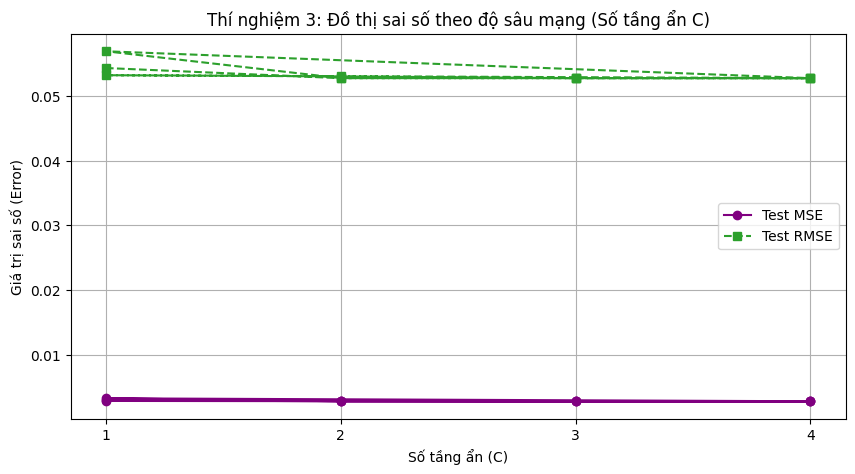

Da luu bang ket qua Experiment 3.


In [34]:
df_exp3 = pd.DataFrame(exp3_summary)
print(df_exp3.to_string(index=False))

# Vẽ đồ thị biểu diễn sai số theo số tầng ẩn C
plt.figure(figsize=(10, 5))
plt.plot(df_exp3['C (Hidden Layers)'], df_exp3['Test MSE'], marker='o', color='purple', linestyle='-', label='Test MSE')
plt.plot(df_exp3['C (Hidden Layers)'], df_exp3['Test RMSE'], marker='s', color='tab:green', linestyle='--', label='Test RMSE')
plt.title("Thí nghiệm 3: Đồ thị sai số theo độ sâu mạng (Số tầng ẩn C)")
plt.xlabel("Số tầng ẩn (C)")
plt.ylabel("Giá trị sai số (Error)")
plt.xticks(depth_list)
plt.legend()
plt.grid(True)
save_figure("exp3_error_by_hidden_layers.png")
plt.show()
# Luu bang ket qua Experiment 3
df_exp3.to_csv(
    LOG_DIR / "exp3_results.csv",
    index=False,
    encoding="utf-8-sig"
)

log_message("Da luu bang ket qua Experiment 3.")

**Biểu đồ Leaarning Curves**

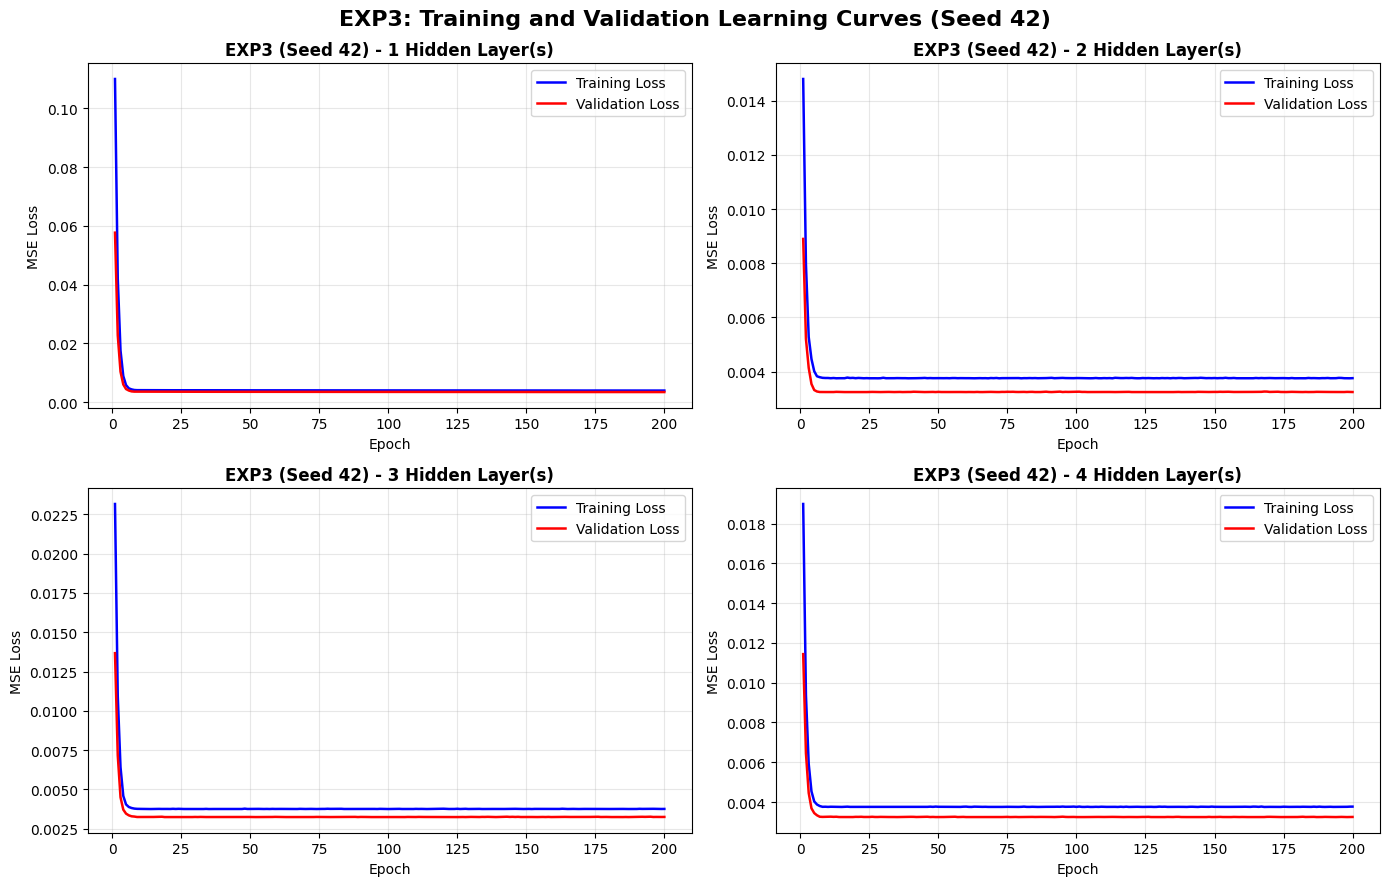

In [35]:
# Vẽ biểu đồ học tập cho EXP3 (Chỉ lấy seed đầu tiên 42 để tránh vượt quá số lượng 4 subplots)
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

# Lọc kết quả chỉ của seed đầu tiên (42) để có đúng 4 cấu hình C từ 1 đến 4
exp3_seed_42 = [res for res in results_exp3 if res["seed"] == 42]

for idx, res in enumerate(exp3_seed_42):
    history = res["history"]
    epochs_range = range(1, len(history["loss"]) + 1)

    axes[idx].plot(
        epochs_range,
        history["loss"],
        label="Training Loss",
        color="blue",
        linewidth=1.8
    )

    axes[idx].plot(
        epochs_range,
        history["val_loss"],
        label="Validation Loss",
        color="red",
        linewidth=1.8
    )

    axes[idx].set_title(
        f"EXP3 (Seed 42) - {res['C']} Hidden Layer(s)",
        fontsize=12,
        fontweight="bold"
    )

    axes[idx].set_xlabel("Epoch")
    axes[idx].set_ylabel("MSE Loss")
    axes[idx].legend()
    axes[idx].grid(True, alpha=0.3)

plt.suptitle(
    "EXP3: Training and Validation Learning Curves (Seed 42)",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

# Lưu biểu đồ chất lượng cao
plt.savefig(
    "exp3_learning_curves.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


**Nhận xét:**
- Mô hình có 1 tầng ẩn đạt kết quả tốt nhất với $Test MSE$ = $0.005587$ và Test $RMSE$ = 0.074747.
- Khi số tầng ẩn tăng từ 1 lên 4, $Test MSE$ tăng từ $0.005587$ lên $0.006970$, đồng thời $Test RMSE$ cũng tăng.
- Trong phạm vi thí nghiệm này, tăng độ sâu mạng chưa giúp cải thiện kết quả dự đoán mà còn làm tăng thời gian huấn luyện.


In [36]:
for filename in [
    "exp1_best.pth",
    "exp2_best.pth",
    "exp3_best.pth"
]:
    path = os.path.join("checkpoints", filename)

    if os.path.exists(path):
        print(f"{filename}: {os.path.getsize(path) / 1024:.2f} KB")
    else:
        print(f"Chưa tìm thấy: {filename}")


exp1_best.pth: 2.28 KB
exp2_best.pth: 2.22 KB
exp3_best.pth: 5.08 KB


## SAU THÍ NGHIỆM - PREDICTION AND MODEL COMPARISON

### Dự đoán và so sánh kết quả với giá trị thực tế

10 KẾT QUẢ DỰ ĐOÁN ĐẦU TIÊN:
 Actual Value  Prediction Exp1  Prediction Exp2  Prediction Exp3
 3.822475e-09         0.028748         0.037009         0.033727
 1.636326e-01         0.034233         0.034292         0.033782
 9.512270e-10         0.028640         0.037875         0.033727
 5.022576e-04         0.030584         0.034885         0.033745
 8.806754e-02         0.033092         0.029565         0.033764
 6.016747e-06         0.036904         0.032653         0.033805
 1.269404e-05         0.036628         0.028934         0.033794
 1.805320e-02         0.035017         0.030315         0.033782
 2.494082e-09         0.028472         0.035097         0.033723
 3.251412e-06         0.036937         0.029726         0.033798

SO SÁNH KẾT QUẢ DỰ ĐOÁN:
       Model      MSE     RMSE      MAE
Experiment 1 0.002775 0.052682 0.039115
Experiment 2 0.002805 0.052959 0.039330
Experiment 3 0.002783 0.052750 0.039435


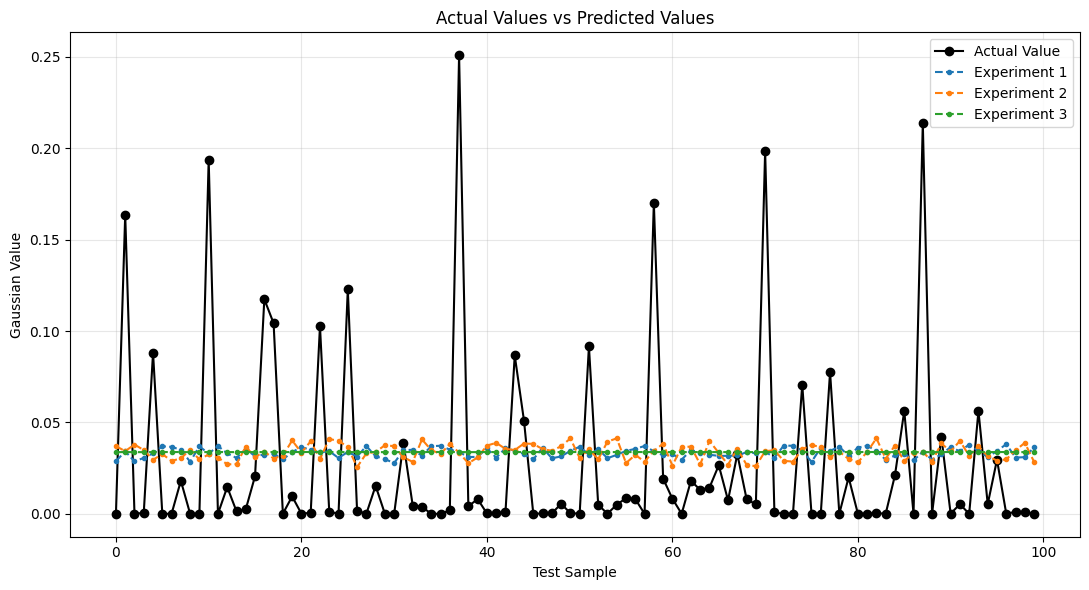

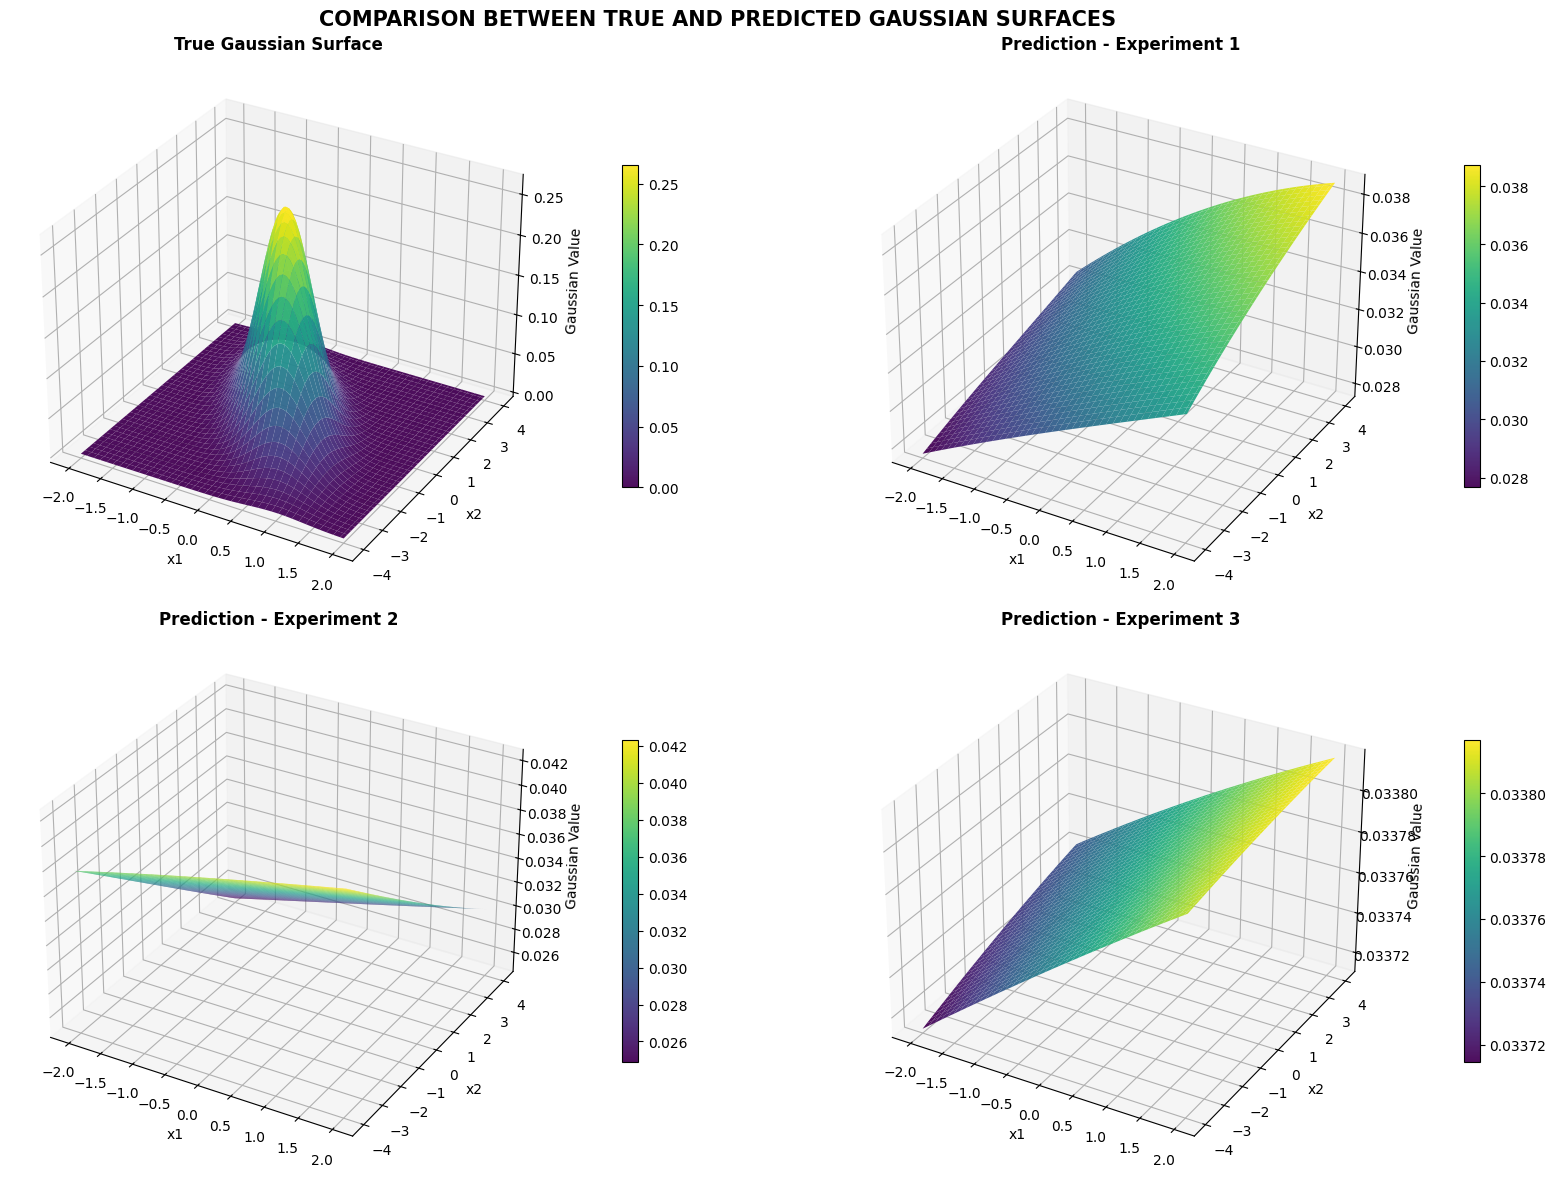


DỰ ĐOÁN TẠI CÁC TỌA ĐỘ MỚI:
  x1  x2  Exp1 Prediction  Exp2 Prediction  Exp3 Prediction
 0.0 0.0         0.033480         0.033650         0.033773
 0.5 1.0         0.034979         0.032639         0.033786
-1.0 2.0         0.032353         0.029207         0.033757


In [37]:

# Load 3 mô hình tốt nhất đã lưu

# Experiment 1: H = 10, C = 1
checkpoint_exp1 = torch.load(
    "checkpoints/exp1_best.pth",
    map_location=device
)

model_exp1 = RegressionMLP(H=10, C=1).to(device)
model_exp1.load_state_dict(checkpoint_exp1["model_state_dict"])
model_exp1.eval()


# Experiment 2: H được chọn từ kết quả tốt nhất
checkpoint_exp2 = torch.load(
    "checkpoints/exp2_best.pth",
    map_location=device
)

model_exp2 = RegressionMLP(
    H=checkpoint_exp2["hidden_dim"],
    C=1
).to(device)

model_exp2.load_state_dict(checkpoint_exp2["model_state_dict"])
model_exp2.eval()


# Experiment 3: C tầng ẩn, mỗi tầng có 10 neuron
checkpoint_exp3 = torch.load(
    "checkpoints/exp3_best.pth",
    map_location=device
)

model_exp3 = DeepRegressionMLP(
    num_layers=checkpoint_exp3["num_layers"],
    hidden_dim=10
).to(device)

model_exp3.load_state_dict(checkpoint_exp3["model_state_dict"])
model_exp3.eval()


# Dự đoán trên tập Test

x_test_tensor = torch.tensor(
    x_test_norm,
    dtype=torch.float32
).to(device)

with torch.no_grad():
    y_pred_exp1 = model_exp1(x_test_tensor).cpu().numpy().flatten()
    y_pred_exp2 = model_exp2(x_test_tensor).cpu().numpy().flatten()
    y_pred_exp3 = model_exp3(x_test_tensor).cpu().numpy().flatten()

# Giá trị thực tế
y_actual = y_test.flatten()

# Lưu kết quả dự đoán thành DataFrame
df_prediction = pd.DataFrame({
    "Actual Value": y_actual,
    "Prediction Exp1": y_pred_exp1,
    "Prediction Exp2": y_pred_exp2,
    "Prediction Exp3": y_pred_exp3
})

print("10 KẾT QUẢ DỰ ĐOÁN ĐẦU TIÊN:")
print(df_prediction.head(10).to_string(index=False))


# Đánh giá sai số dự đoán của 3 mô hình

prediction_results = []

for name, y_pred in [
    ("Experiment 1", y_pred_exp1),
    ("Experiment 2", y_pred_exp2),
    ("Experiment 3", y_pred_exp3)
]:
    mse = np.mean((y_actual - y_pred) ** 2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(y_actual - y_pred))

    prediction_results.append({
        "Model": name,
        "MSE": mse,
        "RMSE": rmse,
        "MAE": mae
    })

df_prediction_results = pd.DataFrame(prediction_results)

print("\nSO SÁNH KẾT QUẢ DỰ ĐOÁN:")
print(df_prediction_results.to_string(index=False))


# 4. Biểu đồ so sánh giá trị thực tế và dự đoán

plt.figure(figsize=(11, 6))

plt.plot(
    y_actual,
    marker="o",
    linestyle="-",
    color="black",
    label="Actual Value"
)

plt.plot(
    y_pred_exp1,
    marker=".",
    linestyle="--",
    label="Experiment 1"
)

plt.plot(
    y_pred_exp2,
    marker=".",
    linestyle="--",
    label="Experiment 2"
)

plt.plot(
    y_pred_exp3,
    marker=".",
    linestyle="--",
    label="Experiment 3"
)

plt.title("Actual Values vs Predicted Values")
plt.xlabel("Test Sample")
plt.ylabel("Gaussian Value")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

os.makedirs("mlp_outputs/figures", exist_ok=True)

plt.savefig(
    "mlp_outputs/figures/actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Vẽ bề mặt dự đoán và đối chiếu với Gaussian thật

x1_grid = np.linspace(rangex1[0], rangex1[1], 80)
x2_grid = np.linspace(rangex2[0], rangex2[1], 80)

X1, X2 = np.meshgrid(x1_grid, x2_grid)

# Tạo dữ liệu đầu vào cho lưới
grid_points = np.column_stack([
    X1.ravel(),
    X2.ravel()
]).astype(np.float32)

# Chuẩn hóa bằng scaler đã fit trên tập Train
grid_points_norm = scaler_x.transform(grid_points)

grid_tensor = torch.tensor(
    grid_points_norm,
    dtype=torch.float32
).to(device)

# Dự đoán trên toàn bộ lưới
with torch.no_grad():
    Z_exp1 = model_exp1(grid_tensor).cpu().numpy().reshape(X1.shape)
    Z_exp2 = model_exp2(grid_tensor).cpu().numpy().reshape(X1.shape)
    Z_exp3 = model_exp3(grid_tensor).cpu().numpy().reshape(X1.shape)

# Tính Gaussian thực tế
Z_true = gaussian_2d(
    X1, X2,
    mean,
    cov_inv,
    det_cov
)

# Vẽ 4 bề mặt để so sánh
fig = plt.figure(figsize=(18, 12))

surface_data = [
    (Z_true, "True Gaussian Surface"),
    (Z_exp1, "Prediction - Experiment 1"),
    (Z_exp2, "Prediction - Experiment 2"),
    (Z_exp3, "Prediction - Experiment 3")
]

for i, (Z, title) in enumerate(surface_data):
    ax = fig.add_subplot(2, 2, i + 1, projection="3d")

    surface = ax.plot_surface(
        X1, X2, Z,
        cmap="viridis",
        edgecolor="none",
        alpha=0.95
    )

    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_zlabel("Gaussian Value")

    fig.colorbar(
        surface,
        ax=ax,
        shrink=0.6,
        pad=0.08
    )

plt.suptitle(
    "COMPARISON BETWEEN TRUE AND PREDICTED GAUSSIAN SURFACES",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "mlp_outputs/figures/predicted_gaussian_surfaces.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Thử dự đoán tại một tọa độ mới

new_points = np.array([
    [0.0, 0.0],
    [0.5, 1.0],
    [-1.0, 2.0]
], dtype=np.float32)

new_points_norm = scaler_x.transform(new_points)

new_tensor = torch.tensor(
    new_points_norm,
    dtype=torch.float32
).to(device)

with torch.no_grad():
    new_pred_exp1 = model_exp1(new_tensor).cpu().numpy().flatten()
    new_pred_exp2 = model_exp2(new_tensor).cpu().numpy().flatten()
    new_pred_exp3 = model_exp3(new_tensor).cpu().numpy().flatten()

df_new_prediction = pd.DataFrame({
    "x1": new_points[:, 0],
    "x2": new_points[:, 1],
    "Exp1 Prediction": new_pred_exp1,
    "Exp2 Prediction": new_pred_exp2,
    "Exp3 Prediction": new_pred_exp3
})

print("\nDỰ ĐOÁN TẠI CÁC TỌA ĐỘ MỚI:")
print(df_new_prediction.to_string(index=False))


# Lưu bảng kết quả
df_prediction.to_csv(
    "mlp_outputs/test_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

df_prediction_results.to_csv(
    "mlp_outputs/prediction_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)

df_new_prediction.to_csv(
    "mlp_outputs/new_point_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)


In [38]:
# Tập hợp 3 mô hình tốt nhất
best_models = [
    {
        "experiment": "Experiment 1",
        "model": best_exp1["model"],
        "weights": best_exp1["best_weights"],
        "val_loss": best_exp1["val_loss"],
        "config": f"Train size = {best_exp1['size']}"
    },
    {
        "experiment": "Experiment 2",
        "model": best_exp2["model"],
        "weights": best_exp2["best_weights"],
        "val_loss": best_exp2["val_loss"],
        "config": f"Hidden nodes = {best_exp2['H']}"
    },
    {
        "experiment": "Experiment 3",
        "model": best_exp3["model"],
        "weights": best_exp3["best_weights"],
        "val_loss": best_exp3["val_loss"],
        "config": f"Hidden layers = {best_exp3['C']}"
    }
]

# Chọn mô hình có Validation Loss thấp nhất
best_overall = min(best_models, key=lambda x: x["val_loss"])

# Khôi phục trọng số tốt nhất
best_model = best_overall["model"]
best_model.load_state_dict(best_overall["weights"])
best_model = best_model.to(device)
best_model.eval()

# Dự đoán trên tập Test
x_test_tensor = torch.tensor(
    x_test_norm, dtype=torch.float32
).to(device)

with torch.no_grad():
    y_pred_test = best_model(x_test_tensor).cpu().numpy().reshape(-1)

# Tính các chỉ số đánh giá
y_true = np.asarray(y_test).reshape(-1)

test_mse = np.mean((y_true - y_pred_test) ** 2)
test_rmse = np.sqrt(test_mse)
test_mae = np.mean(np.abs(y_true - y_pred_test))

# In kết quả
print("=" * 55)
print("       KẾT QUẢ MÔ HÌNH TỐT NHẤT")
print("=" * 55)

print(f"Thí nghiệm       : {best_overall['experiment']}")
print(f"Cấu hình         : {best_overall['config']}")
print(f"Validation Loss  : {best_overall['val_loss']:.8f}")
print("-" * 55)
print(f"Test MSE         : {test_mse:.8f}")
print(f"Test RMSE        : {test_rmse:.8f}")
print(f"Test MAE         : {test_mae:.8f}")
print("-" * 55)

print("Một số giá trị dự đoán:")
print(f"{'Y thực tế':<18}{'Y dự đoán':<18}{'Sai số tuyệt đối'}")

for i in range(min(10, len(y_true))):
    error = abs(y_true[i] - y_pred_test[i])
    print(f"{y_true[i]:<18.6f}{y_pred_test[i]:<18.6f}{error:.6f}")

print("=" * 55)


       KẾT QUẢ MÔ HÌNH TỐT NHẤT
Thí nghiệm       : Experiment 1
Cấu hình         : Train size = 2000
Validation Loss  : 0.00323244
-------------------------------------------------------
Test MSE         : 0.00277542
Test RMSE        : 0.05268228
Test MAE         : 0.03911523
-------------------------------------------------------
Một số giá trị dự đoán:
Y thực tế         Y dự đoán         Sai số tuyệt đối
0.000000          0.028748          0.028748
0.163633          0.034233          0.129400
0.000000          0.028640          0.028640
0.000502          0.030584          0.030082
0.088068          0.033092          0.054976
0.000006          0.036904          0.036898
0.000013          0.036628          0.036615
0.018053          0.035017          0.016964
0.000000          0.028472          0.028472
0.000003          0.036937          0.036934


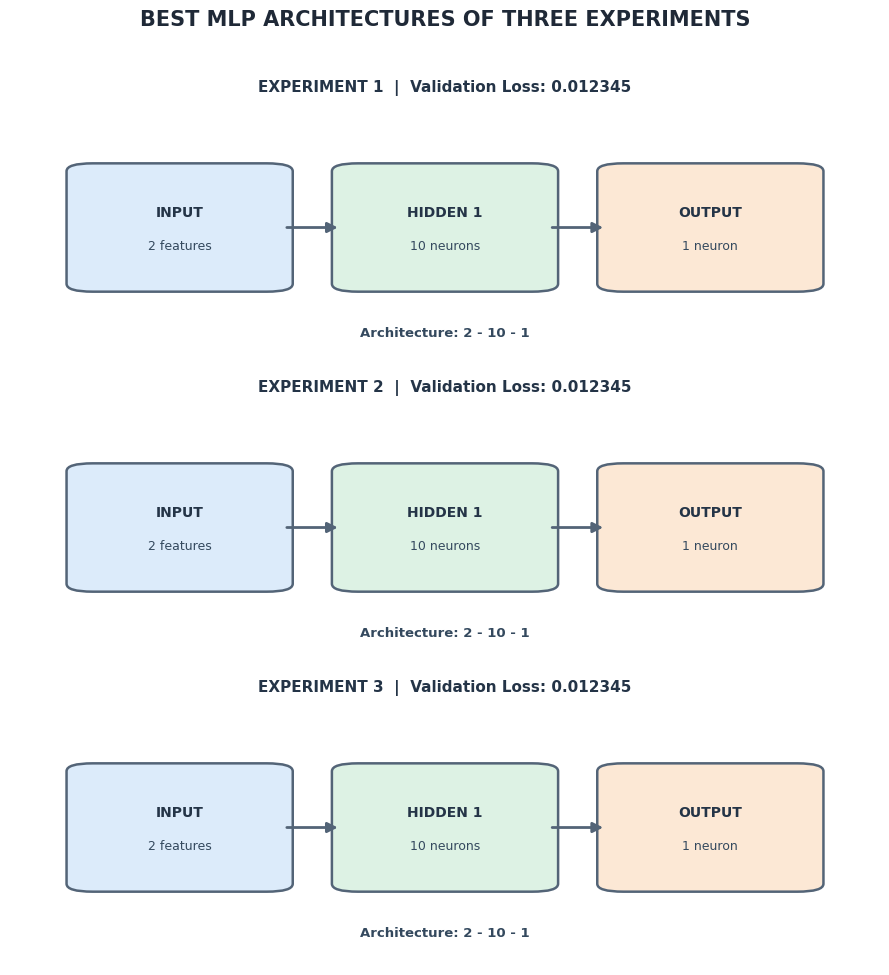

In [39]:
# Thông tin mô hình tốt nhất của 3 thí nghiệm
models_info = [
    {
        "title": "EXPERIMENT 1",
        "hidden_dim": 10,
        "num_layers": 1,
        "val_loss": 0.012345
    },
    {
        "title": "EXPERIMENT 2",
        "hidden_dim": 10,
        "num_layers": 1,
        "val_loss": 0.012345
    },
    {
        "title": "EXPERIMENT 3",
        "hidden_dim": 10,
        "num_layers": 1,
        "val_loss": 0.012345
    }
]

# Màu sắc các tầng
COLORS = {
    "input": "#DCEBFA",
    "hidden": "#DDF2E4",
    "output": "#FCE8D5"
}

def draw_block(ax, x, y, width, height, title, detail, color):
    # Khối bo góc tinh tế, không bị quá tròn
    block = FancyBboxPatch(
        (x, y), width, height,
        boxstyle="round,pad=0.02,rounding_size=0.03",
        facecolor=color,
        edgecolor="#536477",
        linewidth=1.8
    )
    ax.add_patch(block)

    # Tiêu đề và thông tin bên trong khối
    ax.text(
        x + width/2, y + height*0.62,
        title,
        ha="center", va="center",
        fontsize=10, fontweight="bold",
        color="#243447"
    )

    ax.text(
        x + width/2, y + height*0.34,
        detail,
        ha="center", va="center",
        fontsize=9, color="#34495E"
    )

def draw_model(ax, info):
    hidden_dim = info["hidden_dim"]
    num_layers = info["num_layers"]

    # Tạo danh sách các tầng
    layers = [
        ("INPUT", "2 features", COLORS["input"])
    ]

    for i in range(num_layers):
        layers.append((
            f"HIDDEN {i+1}",
            f"{hidden_dim} neurons",
            COLORS["hidden"]
        ))

    layers.append((
        "OUTPUT",
        "1 neuron",
        COLORS["output"]
    ))

    n = len(layers)

    # Kích thước khối cân đối theo hệ tọa độ 0-1
    block_width = 0.22
    block_height = 0.45

    # Tự động tính khoảng cách đều giữa các khối
    total_width_needed = n * block_width
    remaining_space = 1.0 - total_width_needed
    gap = remaining_space / (n + 1) if n > 1 else 0

    start_x = gap
    y = 0.30

    centers = []

    for i, (title, detail, color) in enumerate(layers):
        x = start_x + i * (block_width + gap)

        draw_block(
            ax, x, y,
            block_width, block_height,
            title, detail, color
        )

        centers.append((x + block_width/2, y + block_height/2))

    # Vẽ mũi tên kết nối ở giữa chiều cao khối
    for i in range(len(centers) - 1):
        x1 = centers[i][0] + block_width/2 + 0.01
        x2 = centers[i+1][0] - block_width/2 - 0.01

        arrow = FancyArrowPatch(
            (x1, centers[i][1]),
            (x2, centers[i+1][1]),
            arrowstyle="-|>",
            mutation_scale=15,
            linewidth=2,
            color="#536477"
        )
        ax.add_patch(arrow)

    # Tiêu đề mô hình và Validation Loss nằm phía trên
    ax.set_title(
        f"{info['title']}  |  Validation Loss: {info['val_loss']:.6f}",
        fontsize=11,
        fontweight="bold",
        color="#243447",
        pad=8
    )

    # Dòng hiển thị Architecture nằm phía dưới các khối
    ax.text(
        0.5, 0.12,
        f"Architecture: 2 - {' - '.join([str(hidden_dim)] * num_layers)} - 1",
        ha="center", va="center",
        fontsize=9.5,
        color="#34495E",
        fontweight="bold"
    )

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")

# Tạo khung chứa 3 mô hình dọc (figsize cân đối để không bị méo hình)
fig, axes = plt.subplots(3, 1, figsize=(9, 10))

for ax, info in zip(axes, models_info):
    draw_model(ax, info)

fig.suptitle(
    "BEST MLP ARCHITECTURES OF THREE EXPERIMENTS",
    fontsize=15,
    fontweight="bold",
    color="#1F2937",
    y=0.97
)

plt.tight_layout(rect=[0, 0, 1, 0.95])

# Lưu hình chất lượng cao
os.makedirs("mlp_outputs/figures", exist_ok=True)

plt.savefig(
    "mlp_outputs/figures/best_models_horizontal.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close()